# EDA transcriptômica em LPA

Dados reais, auditoria antes de filtragem. **Execução parcial**: clínica e expressão global executadas; biomaRt pendente. Sem modelos preditivos. Consulte `relatorios/pendencias.md`.

# Fundamentação metodológica

A análise exploratória de dados (EDA) reúne procedimentos gráficos e estatísticos para conhecer a estrutura de um conjunto de observações, identificar inconsistências e formular hipóteses. Na tradição de Tukey (1977), seu objetivo inclui reconhecer aspectos inesperados e avaliar pressupostos, sem confundir descoberta exploratória com confirmação. Em pesquisa biomédica, ela também estabelece a rastreabilidade entre indivíduo, amostra, medida laboratorial e informação clínica. Erros nessa cadeia podem produzir associações aparentemente fortes sem significado biológico.

Em transcriptômica, a unidade independente de observação geralmente é o paciente, enquanto milhares de genes constituem variáveis correlacionadas. A matriz genes × amostras deve ser transposta apenas para métodos que esperam observações nas linhas. Sua orientação não pode ser inferida do tamanho: identificadores, cabeçalhos e tipos numéricos fornecem evidências complementares. A correspondência entre amostras e pacientes exige documentação; nesta coorte, a nota da S22 explica os sufixos de sequenciamento. A S5 documenta RNA-seq, mas não substitui a identificação dos cabeçalhos da VST.

Normalização procura reduzir diferenças técnicas, incluindo profundidade e composição das bibliotecas. A transformação estabilizadora de variância (VST), discutida no contexto do DESeq2 por Love, Huber e Anders (2014), busca diminuir a dependência entre média e variância, favorecendo distâncias e visualizações. Seus valores não são contagens brutas nem medidas absolutas diretamente comparáveis a números de moléculas. Não se devem usar VST como entrada de modelos de contagem do DESeq2. Um mínimo compartilhado pode refletir propriedades da transformação: não comprova ausência de transcrição e não permite recuperar zeros de contagem sem os dados e parâmetros originais.

Valores extremos podem refletir diversidade biológica, composição celular, diferenças de processamento ou erro. Ausência de informação também não equivale a ausência de mutação: o código 0 é observação negativa, enquanto campo vazio é disponibilidade desconhecida. Nenhuma exclusão ou imputação deve ser automática na EDA. Mapas de ausência e comparação dos pacientes com e sem informação descrevem padrões, mas não demonstram os mecanismos MCAR, MAR ou MNAR. Em modelagem futura, parâmetros de imputação deverão ser estimados no treinamento, preservando a separação da avaliação.

A correlação entre genes é esperada por regulação compartilhada, composição celular e processos técnicos. Ela implica redundância e multicolinearidade; um coeficiente isolado não identifica causalidade ou contribuição prognóstica independente. Correlações e heatmaps devem usar subconjuntos documentados, evitando uma matriz ilegível e estatisticamente onerosa de todos os pares gênicos. Os 389 genes publicados foram selecionados em comparações clínicas; sua reanálise não constitui seleção independente de Sanz.

A PCA identifica combinações lineares que maximizam a variância observada (Jolliffe e Cadima, 2016). Neste projeto, a estratégia programada usa até 1.000 genes de maior variância positiva, centrados, sem padronização por desvio-padrão. Essa escolha evita atribuir igual peso a genes de variância mínima depois da VST. O número de genes, a fração explicada e os loadings devem ser reportados. Agrupamento Ward usa distância euclidiana no mesmo espaço; heatmaps de expressão usam z-scores apenas para visualização de até 40 genes. PCA e agrupamentos descrevem estrutura; separação visual não mede desempenho preditivo. Sem variáveis de lote e sem dados brutos, não se pode atribuir essa estrutura exclusivamente à biologia nem corrigi-la com segurança.

EDA não supervisionada estuda a matriz sem orientar a seleção pelo desfecho. Colorir projeções posteriormente por variáveis clínicas ajuda a explorar hipóteses, mas introduz interpretação orientada pelos rótulos. APL9 é uma classificação derivada de expressão na publicação original: sua associação com padrões transcriptômicos pode refletir a construção da própria assinatura. Para mortalidade, o problema é adicional: ausência de consolidação é informação posterior ao diagnóstico, não um evento validado nem preditor admissível em um modelo basal. Concordância entre totais publicados e candidatos não estabelece validade individual.

Desfechos raros oferecem pouca informação para estimar parâmetros de alta dimensão. Com aproximadamente 22 eventos potenciais, seleção adaptativa de milhares de genes favorece instabilidade e sobreajuste. A aprendizagem futura deve empregar modelos parcimoniosos, validação que repita todo o pré-processamento e avaliação externa. Selecionar características na coorte inteira antes da validação gera otimismo (Ambroise e McLachlan, 2002; Varma e Simon, 2006). Até filtros não supervisionados dependentes dos dados deverão ser ajustados no treinamento se fizerem parte do procedimento preditivo avaliado.

Testes exploratórios múltiplos exigem uma família definida e controle da taxa de falsas descobertas, como Benjamini–Hochberg (1995). O ajuste não resolve confundimento, circularidade da assinatura, incerteza dos rótulos ou multiplicidade decorrente de escolhas analíticas não registradas. Estimativas descritivas e tamanhos de efeito merecem destaque; valores de p não validam utilidade clínica. Futuramente, PR-AUC deverá ser interpretada em relação à prevalência, juntamente com ROC-AUC, calibração e incerteza (Saito e Rehmsmeier, 2015).

# Referências verificáveis

- Tukey JW. *Exploratory Data Analysis*. Addison-Wesley; 1977.
- Love MI, Huber W, Anders S. Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2. *Genome Biology*. 2014;15:550. https://doi.org/10.1186/s13059-014-0550-8
- Jolliffe IT, Cadima J. Principal component analysis: a review and recent developments. *Philos Trans A*. 2016;374:20150202. https://doi.org/10.1098/rsta.2015.0202
- Durinck S, Spellman PT, Birney E, Huber W. Mapping identifiers for the integration of genomic datasets with the R/Bioconductor package biomaRt. *Nature Protocols*. 2009;4:1184–1191. https://doi.org/10.1038/nprot.2009.97
- Benjamini Y, Hochberg Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. *JRSS B*. 1995;57:289–300. https://doi.org/10.1111/j.2517-6161.1995.tb02031.x
- Ambroise C, McLachlan GJ. Selection bias in gene extraction on the basis of microarray gene-expression data. *PNAS*. 2002;99:6562–6566. https://doi.org/10.1073/pnas.102102699
- Varma S, Simon R. Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics*. 2006;7:91. https://doi.org/10.1186/1471-2105-7-91
- Saito T, Rehmsmeier M. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*. 2015;10:e0118432. https://doi.org/10.1371/journal.pone.0118432
- Lin X et al. Integration of Genomic and Transcriptomic Markers Improves the Prognosis Prediction of Acute Promyelocytic Leukemia. *Clinical Cancer Research*. 2021;27:3683–3694. https://doi.org/10.1158/1078-0432.CCR-20-4375 — PDF efetivamente inspecionado.
- biomaRt: documentação oficial, https://bioconductor.org/packages/biomaRt/ .

Biaggi (2024): guia indicado no pedido, usado como organização pretendida das etapas; conteúdo integral não acessado. Jin et al. (2024): referência incompleta no pedido, não identificada inequivocamente; requer título/DOI/PDF para discussão científica fiel. Não se atribuem a esses textos resultados não verificados.


In [1]:
from pathlib import Path
import sys, json, pandas as pd
from IPython.display import display, Markdown, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'scripts/run.py').exists(), 'Abra a partir de LPA_EDA ou notebooks'
sys.path.insert(0,str(ROOT/'scripts'))
summary=json.loads((ROOT/'relatorios/resumo.json').read_text())
display(pd.Series(summary,dtype=object).to_frame('resultado'))

,resultado
s22_patients,346
s5_samples,323
s5_s22_matches,323
clinical_without_s5,"[APL1, APL100, APL111, APL13, APL160, APL163, ..."
candidate_count,22
candidate_APL9,"{'GII': 17, 'GI': 5}"
candidates_in_s5,22
sanz,"{'Intermediate-risk': 172, 'High-risk': 109, '..."
APL9,"{'GII': 163, 'GI': 160}"
APL9_missing,23


## 1 — Estrutura e procedência

**A. Fundamentação:** Integridade antecede inferência.

**B. Objetivo:** Quais arquivos e registros estão efetivamente disponíveis?

**C. Método:** SHA-256, inspeção de abas, linhas e cabeçalhos; VST com parsing estrito.

**D. Código executável:** os módulos integrais estão nas células finais e em `scripts/`; as células abaixo apresentam os resultados já produzidos.

**E. Resultados reais:**

In [2]:
display(pd.read_csv(ROOT/'tabelas/procedencia_checksums.csv'))
display(pd.read_csv(ROOT/'tabelas/excel_sheets.csv'))

,file,bytes,sha256,processed_utc
0,GSE172057_VST_parte_04.txt.gz,10159407,251dd38049f21f10b7a561a42fa6bd24509d7cfb1d9c16...,2026-10-27T23:43:52.957935+00:00
1,GSE172057_VST_parte_03.txt.gz,15866815,b4c1ef3d96e1c2993fc40cb317ee0feec73cbddae6726a...,2026-10-27T23:43:52.957935+00:00
2,GSE172057_VST_parte_01.txt.gz,23507899,bf026f50c0741e640b72fb9efdc23364fa212e3e762d43...,2026-10-27T23:43:52.957935+00:00
3,3683.pdf,1334473,3a0b4855beb002f420c6617a6588af90e6fa66a1ab5148...,2026-10-27T23:43:52.957935+00:00
4,GSE172057_VST_parte_02.txt.gz,20236315,deb2b7d46d0705a74f4221529a0c26a7bee16f515d849b...,2026-10-27T23:43:52.957935+00:00
5,manifest.json,500,363d60e610a9132eeac65a5f1cea6d88747ae4869f3dbf...,2026-10-27T23:43:52.957935+00:00
6,suplemento_lin_2021.xlsx,537656,cf782160648a686fb50e1209a4415245751a47c198ae29...,2026-10-27T23:43:52.957935+00:00


,sheet,rows_including_title,columns
0,Table S1,7,11
1,Table S2,9,7
2,Table S3,395,12
3,Table S4,37,2
4,Table S5,325,5
5,Table S6,11,4
6,Table S7,59,5
7,Table S8,32,3
8,Table S9,1485,15
9,Table S10,159,7


**F. Interpretação:** Arquivos auditados; união de quatro partes com 36.119 genes × 323 amostras, sem alterar os bytes das linhas de dados.

**G. Implicações para ML:** Sem identidade confiável das amostras, não é válido dividir pacientes em treino/teste.

## 2 — Anotação biomaRt

**A. Fundamentação:** Símbolos e biotipos dependem de release e montagem.

**B. Objetivo:** Quantos IDs são mapeados sem perda?

**C. Método:** R/biomaRt, left join, registro de assembly/release e cache por conjunto de IDs.

**D. Código executável:** os módulos integrais estão nas células finais e em `scripts/`; as células abaixo apresentam os resultados já produzidos.

**E. Resultados reais:**

In [3]:
display(pd.read_csv(ROOT/'tabelas/auditoria_integridade.csv'))

,component,rows,status,decision
0,Excel S22,346.0,auditado,346 pacientes preservados; notas e linha vazia...
1,Excel S5,323.0,auditado,preservado; não equivale à conferência da matriz
2,VST,36119.0,executada,323 colunas de amostras; partes unidas com byt...
3,biomaRt,NaN,não executado,R ausente; anotação e acesso Ensembl ainda nec...
4,segunda versão VST,NaN,não fornecida,transposição não comparada


**F. Interpretação:** Não executada: R ausente; matriz já disponível. Nenhum símbolo ou biotipo foi inventado.

**G. Implicações para ML:** Congelar anotação e documentar equivalências antes da modelagem.

## 3 — Integração de IDs

**A. Fundamentação:** Correspondência exige evidência documental.

**B. Objetivo:** S5 e S22 representam os mesmos pacientes?

**C. Método:** Remover somente sufixos A/C/AC documentados na nota †, conservando os IDs originais.

**D. Código executável:** os módulos integrais estão nas células finais e em `scripts/`; as células abaixo apresentam os resultados já produzidos.

**E. Resultados reais:**

In [4]:
display(pd.read_csv(ROOT/'tabelas/correspondencia_ids.csv'))

,patient_id,original_vst,original_s22,original_s5,status,rule,evidence,ambiguity
0,APL1,NaN,APL1AC,NaN,sem expressão observada,igualdade exata após retirada de sufixo docume...,nota † S22,NaN
1,APL10,APL10,APL10AC,APL10,VST–S22 confirmada,igualdade exata após retirada de sufixo docume...,nota † S22,NaN
2,APL100,NaN,APL100AC,NaN,sem expressão observada,igualdade exata após retirada de sufixo docume...,nota † S22,NaN
3,APL101,APL101,APL101AC,APL101,VST–S22 confirmada,igualdade exata após retirada de sufixo docume...,nota † S22,NaN
4,APL103,APL103,APL103AC,APL103,VST–S22 confirmada,igualdade exata após retirada de sufixo docume...,nota † S22,NaN
...,...,...,...,...,...,...,...,...
341,APL95,NaN,APL95AC,NaN,sem expressão observada,igualdade exata após retirada de sufixo docume...,nota † S22,NaN
342,APL96,APL96,APL96AC,APL96,VST–S22 confirmada,igualdade exata após retirada de sufixo docume...,nota † S22,NaN
343,APL97,APL97,APL97AC,APL97,VST–S22 confirmada,igualdade exata após retirada de sufixo docume...,nota † S22,NaN
344,APL98,APL98,APL98AC,APL98,VST–S22 confirmada,igualdade exata após retirada de sufixo docume...,nota † S22,NaN


**F. Interpretação:** 323 correspondências VST–S5–S22 confirmadas; IDs preservados.

**G. Implicações para ML:** Evitar amostras do mesmo paciente em partições distintas.

## 4 — Características basais

**A. Fundamentação:** Estatísticas descritivas delimitam a população observada.

**B. Objetivo:** Como a coorte se distribui por idade, sexo, Sanz e APL9?

**C. Método:** Resumo numérico de idade e frequências com denominador total; WBC e plaquetas mantidos categóricos.

**D. Código executável:** os módulos integrais estão nas células finais e em `scripts/`; as células abaixo apresentam os resultados já produzidos.

**E. Resultados reais:**

In [5]:
display(pd.read_csv(ROOT/'tabelas/idade_descritiva.csv'))
display(pd.read_csv(ROOT/'tabelas/tabela1_categoricas.csv'))

,variable,count,mean,std,min,25%,50%,75%,max,missing,IQR
0,age,346.0,38.427746,11.992352,18.0,28.0,38.0,47.0,65.0,0,19.0


,variable,level,n,percent_total,denominator
0,sex,Male,188,54.335260,346
1,sex,Female,158,45.664740,346
2,sanz,Intermediate-risk,172,49.710983,346
3,sanz,High-risk,109,31.502890,346
4,sanz,Low-risk,65,18.786127,346
5,consolidation,with ATO,170,49.132948,346
6,consolidation,without ATO,154,44.508671,346
7,consolidation,Ausente,22,6.358382,346
8,wbc_gt10,0,237,68.497110,346
9,wbc_gt10,1,109,31.502890,346


**F. Interpretação:** 346 pacientes; idade mediana 38 anos. Os grupos não demonstram associação prognóstica independente.

**G. Implicações para ML:** Descrever diferenças de distribuição e não usar consolidação como preditor basal.

## 5 — Ausências e consistência

**A. Fundamentação:** Ausência não equivale a teste mutacional negativo.

**B. Objetivo:** Quais variáveis têm disponibilidade limitada?

**C. Método:** Completude por paciente/variável, padrões e comparação descritiva, sem imputação.

**D. Código executável:** os módulos integrais estão nas células finais e em `scripts/`; as células abaixo apresentam os resultados já produzidos.

**E. Resultados reais:**

In [6]:
display(pd.read_csv(ROOT/'tabelas/completude_clinica.csv'))
display(pd.read_csv(ROOT/'tabelas/consistencia_clinica.csv'))

,variable,observed,missing,missing_fraction
0,sex,346,0,0.000000
1,age,346,0,0.000000
2,sanz,346,0,0.000000
3,consolidation,324,22,0.063584
4,wbc_gt10,346,0,0.000000
5,platelets_ge40,345,1,0.002890
6,FLT3_ITD,346,0,0.000000
7,FLT3_TKD,346,0,0.000000
8,WT1,346,0,0.000000
9,NRAS,346,0,0.000000


,patient_id,issue,observed,reconstruction


**F. Interpretação:** 23 ausências em APL9; o limiar plaquetário não permite recuperar a contagem original.

**G. Implicações para ML:** Imputação futura estimada apenas no treinamento; não presumir mecanismo de ausência.

## 6 — Distribuição VST

**A. Fundamentação:** VST não é contagem; piso não significa ausência biológica.

**B. Objetivo:** Há valores inválidos, duplicatas, genes invariantes ou amostras atípicas?

**C. Método:** Histograma, KDE com semente, estatísticas por gene/amostra e tolerância absoluta 1e-4 para o piso.

**D. Código executável:** os módulos integrais estão nas células finais e em `scripts/`; as células abaixo apresentam os resultados já produzidos.

**E. Resultados reais:**

In [7]:
display(pd.read_csv(ROOT/'tabelas/auditoria_expressao.csv'))
display(pd.read_csv(ROOT/'tabelas/amostras_estatisticas.csv'))

,file,sha256,delimiter,header_fields,row_widths,inconsistent_rows,duplicate_headers,genes,samples,orientation,missing,second_matrix,zero_variance,near_zero_variance,duplicate_gene_rows,duplicate_sample_columns,floor,near_floor_fraction,candidates_with_expression
0,dados_processados/GSE172057_VST_unificada.txt.gz,1328d23813e337239c675e9c5a01fd67bc69a54179145e...,'\t',324,{324: 36119},0,0,36119,323,genes_rows,0,não fornecida; equivalência não verificada,0,0,0,0,3.448441,0.242872,22


,patient_id,count,mean,std,min,25%,50%,75%,max,IQR
0,APL2,36119.0,6.089299,2.866945,3.448441,3.448441,4.798034,8.338539,19.610734,4.890098
1,APL3,36119.0,5.976606,2.916619,3.448441,3.448441,4.601928,8.033962,20.826660,4.585521
2,APL4,36119.0,6.049314,2.790948,3.448441,3.863972,4.783250,8.291209,19.833524,4.427236
3,APL5,36119.0,5.999686,2.878823,3.448441,3.448441,4.625532,8.230964,20.856846,4.782524
4,APL6,36119.0,5.946484,2.853208,3.448441,3.448441,4.504543,8.179105,18.820449,4.730665
...,...,...,...,...,...,...,...,...,...,...
318,APL375,36119.0,6.029687,2.868064,3.448441,3.923291,4.673333,8.081096,20.073252,4.157805
319,APL376,36119.0,6.076934,2.768999,3.448441,3.903707,4.839576,8.254291,20.400899,4.350584
320,APL377,36119.0,6.228689,2.749486,3.448441,3.448441,5.269734,8.437872,21.270475,4.989431
321,APL378,36119.0,6.038782,2.853302,3.448441,3.448441,4.682944,8.277100,20.351968,4.828659


**F. Interpretação:** Executada: 36.119 genes × 323 amostras; sem ausentes, perfis duplicados ou genes invariantes. Parâmetros de tolerância e variância próxima de zero (1e-8) são escolhas computacionais, não limites biológicos.

**G. Implicações para ML:** Não excluir outliers automaticamente; avaliar sensibilidade depois de esclarecer a origem.

## 7 — PCA e agrupamentos

**A. Fundamentação:** Variância e distâncias descrevem heterogeneidade, não predição.

**B. Objetivo:** Existe estrutura global associada a atributos clínicos?

**C. Método:** Até 1.000 genes de maior variância positiva; PCA centrada, Ward/euclidiana; heatmap de 40 genes.

**D. Código executável:** os módulos integrais estão nas células finais e em `scripts/`; as células abaixo apresentam os resultados já produzidos.

**E. Resultados reais:**

In [8]:
display(pd.read_csv(ROOT/'tabelas/pca_global_variance.csv'))
display(pd.read_csv(ROOT/'tabelas/pca_global_scores.csv'))

,component,variance_ratio
0,PC1,0.208470
1,PC2,0.130278
2,PC3,0.069193
3,PC4,0.051764
4,PC5,0.045277
5,PC6,0.038592
6,PC7,0.036521
7,PC8,0.027274
8,PC9,0.020157
9,PC10,0.016548


,patient_id,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,APL2,56.707719,5.007754,-3.504419,14.193106,7.990399,1.015782,-5.200867,-0.200280,12.831391,-0.208453
1,APL3,-13.673658,21.210498,-7.680403,-17.792839,-7.155975,13.747575,-9.634298,1.408882,-5.199621,-9.774155
2,APL4,-4.421803,-23.259078,14.585509,-5.949577,9.660692,-1.286034,-10.914884,-5.455484,9.558758,-3.568889
3,APL5,11.808981,-20.196860,-4.093260,12.682051,7.746011,13.043566,-11.639278,12.580066,-0.256683,-0.629137
4,APL6,-39.751498,-11.498964,-24.533420,-12.850597,-0.081686,1.597288,5.715510,-8.213615,5.091266,-0.542410
...,...,...,...,...,...,...,...,...,...,...,...
318,APL375,-10.355009,7.987265,-1.453532,-14.484563,-14.510498,-7.450935,-9.171722,2.087618,7.126633,-4.550923
319,APL376,-11.235152,0.948673,6.686817,-9.390125,-4.864507,-12.757304,-9.545217,-2.085787,-7.687950,1.064984
320,APL377,48.287571,-12.510919,14.485042,-4.322126,0.953310,-30.197331,-1.444868,-15.737613,-6.258869,-9.843750
321,APL378,34.021737,-5.034949,1.059142,11.408671,-12.335672,-3.407262,1.362647,-3.525534,-7.776525,-0.382165


**F. Interpretação:** PCA global executada. PCA de protein-coding/lncRNA depende de anotação; ausência de lote limita atribuição biológica.

**G. Implicações para ML:** Refazer seleção/PCA em cada treino quando usados em predição.

## 8 — Relações clínicas e assinaturas

**A. Fundamentação:** Associação descritiva deve considerar circularidade e multiplicidade.

**B. Objetivo:** Sanz e mutações apresentam estrutura em relação a GI/GII?

**C. Método:** Fisher 2×2, qui-quadrado nos demais casos, Cramér V e BH na família declarada; S16 como fonte publicada.

**D. Código executável:** os módulos integrais estão nas células finais e em `scripts/`; as células abaixo apresentam os resultados já produzidos.

**E. Resultados reais:**

In [9]:
display(pd.read_csv(ROOT/'tabelas/associacoes_APL9_exploratorias.csv'))
display(pd.read_csv(ROOT/'tabelas/assinatura_389_publicada.csv'))

,variable,n_complete,test,p,cramers_v,min_expected,q_BH
0,sanz,323,chi-quadrado,2.303026e-15,0.456834,30.712074,2.303026e-14
1,FLT3_ITD,323,Fisher bilateral,2.198581e-05,0.226543,20.804954,1.099290e-04
2,FLT3_TKD,323,Fisher bilateral,9.650602e-02,0.088007,32.198142,2.412651e-01
3,WT1,323,Fisher bilateral,2.283931e-02,0.122086,30.216718,7.613103e-02
4,NRAS,323,Fisher bilateral,3.386661e-01,0.050361,14.860681,5.644435e-01
5,ARID1A,323,Fisher bilateral,6.761426e-01,0.014437,11.888545,8.092996e-01
6,RREB1,323,Fisher bilateral,8.092996e-01,0.011240,8.916409,8.092996e-01
7,KRAS,323,Fisher bilateral,7.845866e-01,0.001902,6.439628,8.092996e-01
8,EBF3,323,Fisher bilateral,7.845866e-01,0.001902,6.439628,8.092996e-01
9,sex,323,Fisher bilateral,2.657796e-01,0.058346,74.798762,5.315593e-01


,ID,Base Mean,Log2 FC*,lfcSE,Stat,P-value,Padj,Gene Symbol,Gene Group,Signature Gene
0,ENSG00000070182,3887.232616,-4.490959,0.285527,-15.728642,9.625406e-56,3.171379e-51,SPTB,Cluster A,NaN
1,ENSG00000168477,491.592579,-4.626356,0.300406,-15.400360,1.627605e-53,2.681316e-49,TNXB,Cluster A,NaN
2,ENSG00000198336,574.576717,-4.845948,0.317985,-15.239532,1.932494e-52,2.122394e-48,MYL4,Cluster A,NaN
3,ENSG00000167994,245.590490,-4.447771,0.295297,-15.062009,2.879054e-51,2.371477e-47,RAB3IL1,Cluster A,NaN
4,ENSG00000143416,2487.364715,-5.107273,0.340253,-15.010210,6.294813e-51,4.148030e-47,SELENBP1,Cluster A,NaN
...,...,...,...,...,...,...,...,...,...,...
384,ENSG00000185686,351.591535,2.188341,0.516143,4.239799,2.237204e-05,2.370141e-04,PRAME,NaN,NaN
385,ENSG00000182492,166.232677,-3.128261,0.750935,-4.165820,3.102360e-05,3.166560e-04,BGN,NaN,NaN
386,ENSG00000168542,195.282197,-2.916807,0.755805,-3.859205,1.137564e-04,1.001081e-03,COL3A1,NaN,NaN
387,ENSG00000115461,357.826331,-2.333031,0.623864,-3.739648,1.842781e-04,1.533231e-03,IGFBP5,NaN,NaN


**F. Interpretação:** Ver resultados calculados abaixo; células esparsas limitam testes assintóticos. Os 389 genes já foram selecionados por grupos clínicos.

**G. Implicações para ML:** Não interpretar reutilização desta coorte como validação independente de APL9.

## 9 — Mortalidade candidata

**A. Fundamentação:** Totais concordantes não validam eventos individuais.

**B. Objetivo:** Os registros sem consolidação reproduzem os agregados?

**C. Método:** Indicador inferido, lista individual e conferência S5–VST, sem converter em óbito confirmado.

**D. Código executável:** os módulos integrais estão nas células finais e em `scripts/`; as células abaixo apresentam os resultados já produzidos.

**E. Resultados reais:**

In [10]:
display(pd.read_csv(ROOT/'tabelas/candidatos_correspondencia_vst.csv'))
display(pd.read_csv(ROOT/'tabelas/contingencia_APL9_early_death_candidate.csv'))

,patient_id,original_s22,sanz,APL9,original_vst,outcome_status
0,APL215,APL215A,High-risk,GI,APL215,inferido; não óbito individual confirmado
1,APL216,APL216A,Intermediate-risk,GII,APL216,inferido; não óbito individual confirmado
2,APL218,APL218A,High-risk,GII,APL218,inferido; não óbito individual confirmado
3,APL219,APL219A,Intermediate-risk,GII,APL219,inferido; não óbito individual confirmado
4,APL220,APL220A,Intermediate-risk,GI,APL220,inferido; não óbito individual confirmado
5,APL221,APL221A,High-risk,GII,APL221,inferido; não óbito individual confirmado
6,APL231,APL231,Intermediate-risk,GII,APL231,inferido; não óbito individual confirmado
7,APL246,APL246,Intermediate-risk,GI,APL246,inferido; não óbito individual confirmado
8,APL253,APL253,Intermediate-risk,GII,APL253,inferido; não óbito individual confirmado
9,APL256,APL256,High-risk,GII,APL256,inferido; não óbito individual confirmado


,APL9,False,True
0,Ausente,23,0
1,GI,155,5
2,GII,146,17


**F. Interpretação:** 22 candidatos (5 GI e 17 GII), todos na S5 e VST. APL9 é observado, mortalidade é inferida, evento individual confirmado está indisponível.

**G. Implicações para ML:** Não treinar modelos de morte precoce antes de confirmar rótulos e temporalidade.

## 10 — Planejamento posterior

**A. Fundamentação:** Poucos eventos e muitos genes favorecem otimismo e instabilidade.

**B. Objetivo:** Como comparar valor incremental com avaliação honesta?

**C. Método:** Planejar clínico, clínico+APL9 e clínico+assinatura parcimoniosa com validação interna e externa.

**D. Código executável:** os módulos integrais estão nas células finais e em `scripts/`; as células abaixo apresentam os resultados já produzidos.

**E. Resultados reais:**

In [11]:
display(pd.read_csv(ROOT/'tabelas/auditoria_integridade.csv'))

,component,rows,status,decision
0,Excel S22,346.0,auditado,346 pacientes preservados; notas e linha vazia...
1,Excel S5,323.0,auditado,preservado; não equivale à conferência da matriz
2,VST,36119.0,executada,323 colunas de amostras; partes unidas com byt...
3,biomaRt,NaN,não executado,R ausente; anotação e acesso Ensembl ainda nec...
4,segunda versão VST,NaN,não fornecida,transposição não comparada


**F. Interpretação:** Nenhum modelo treinado; nenhuma métrica preditiva calculada.

**G. Implicações para ML:** Pré-processamento dentro do treinamento; ROC-AUC, PR-AUC, calibração e incerteza somente em etapa posterior.

## Figuras executadas

Gráficos clínicos e transcriptômicos calculados com os dados recebidos.

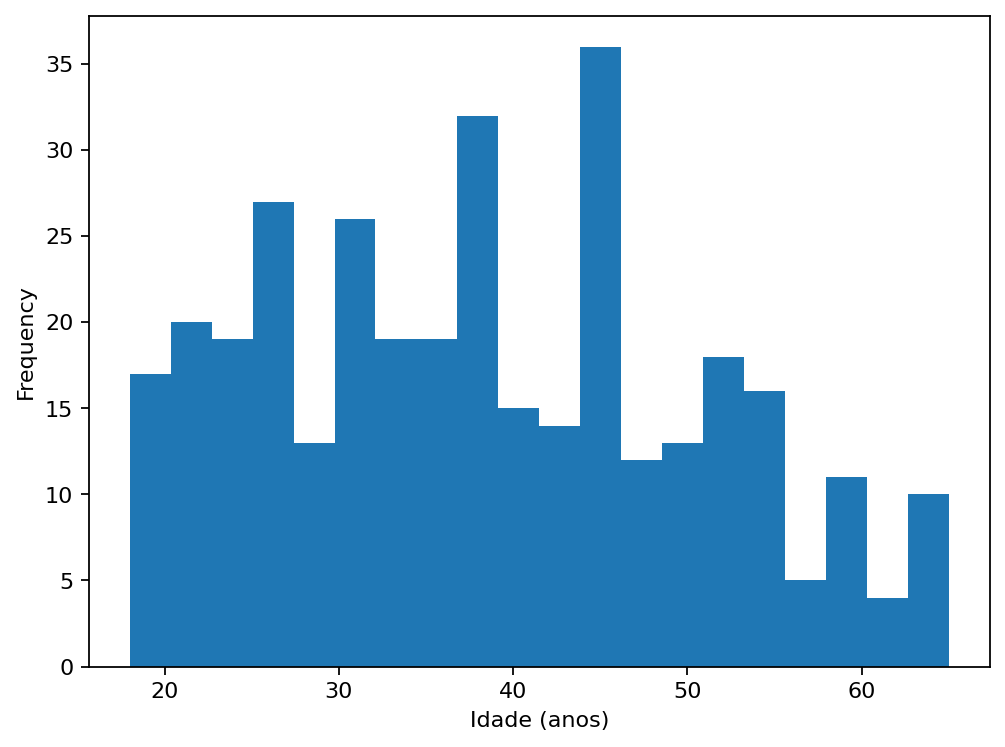

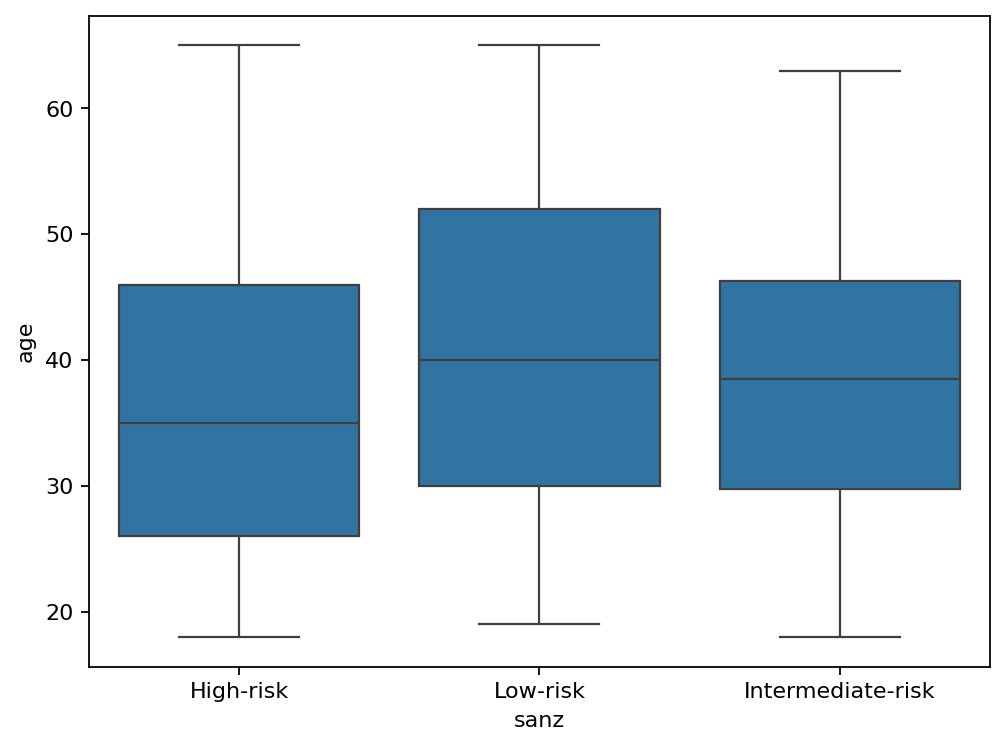

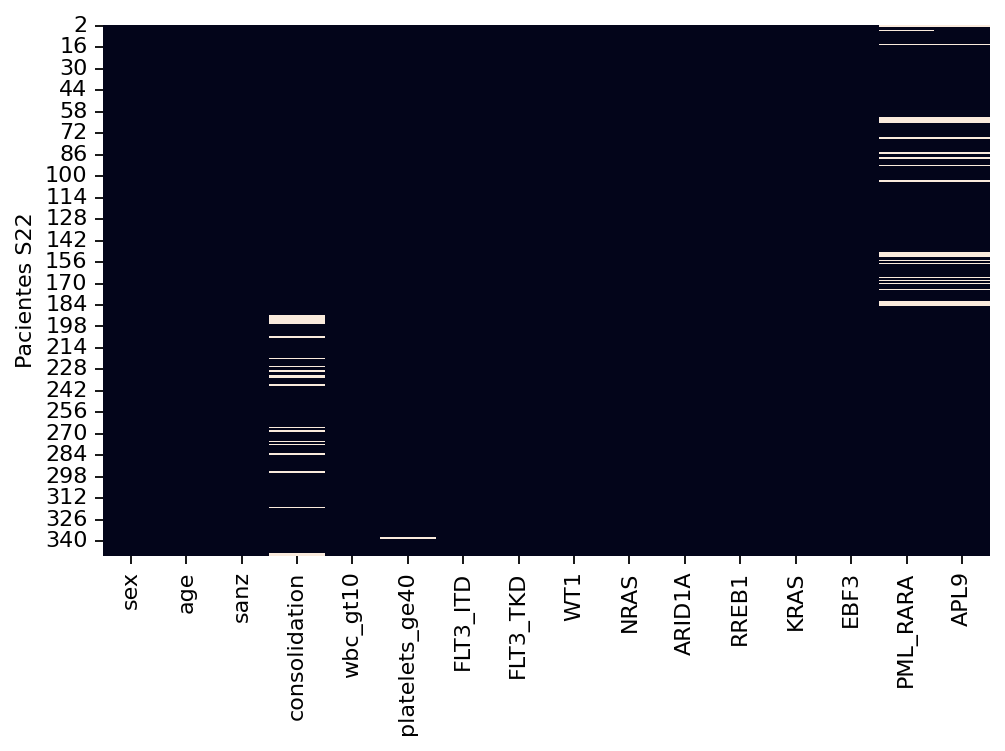

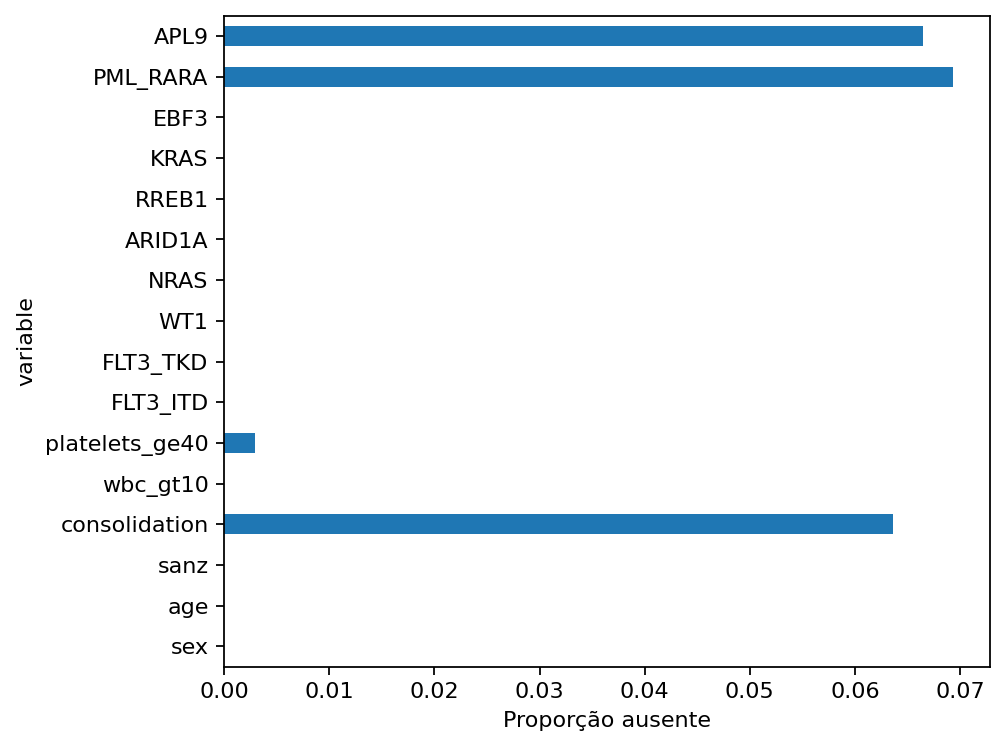

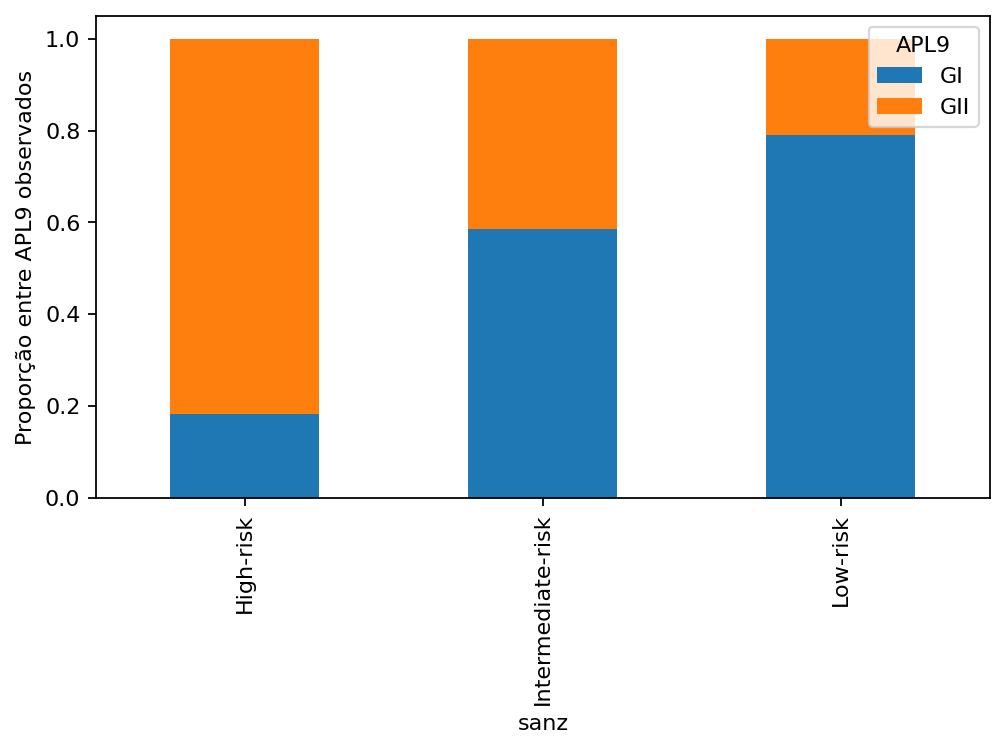

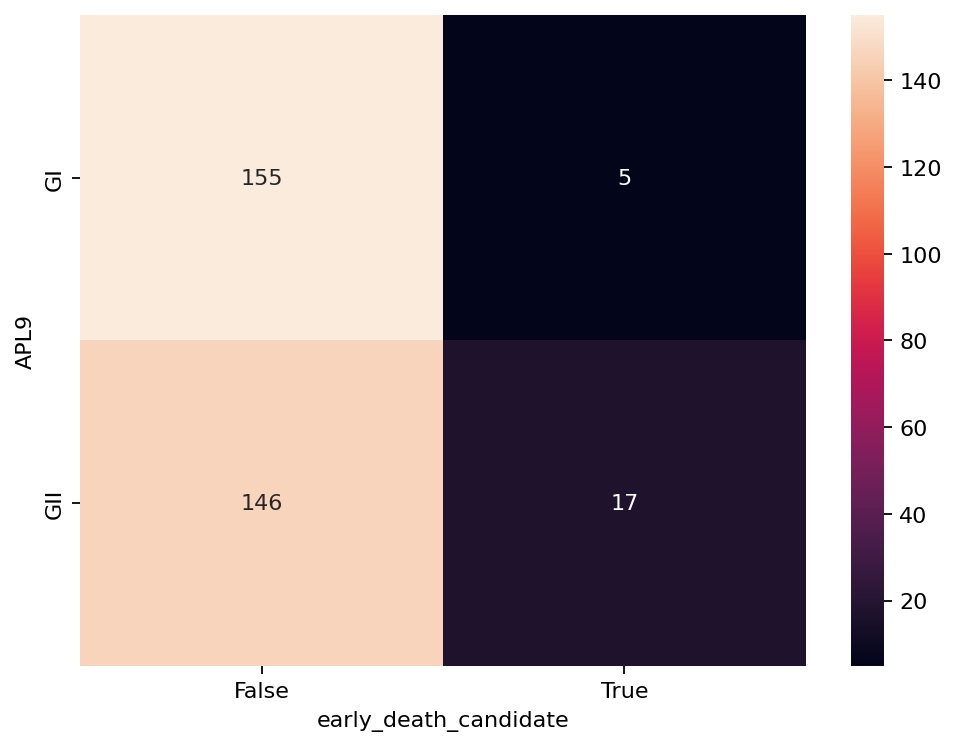

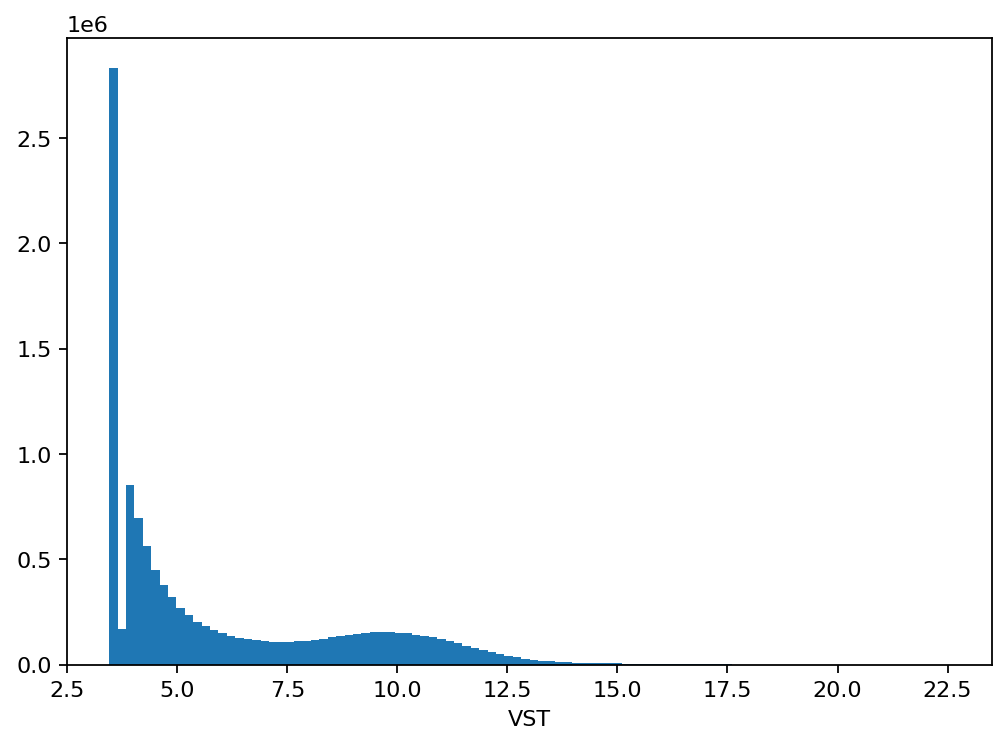

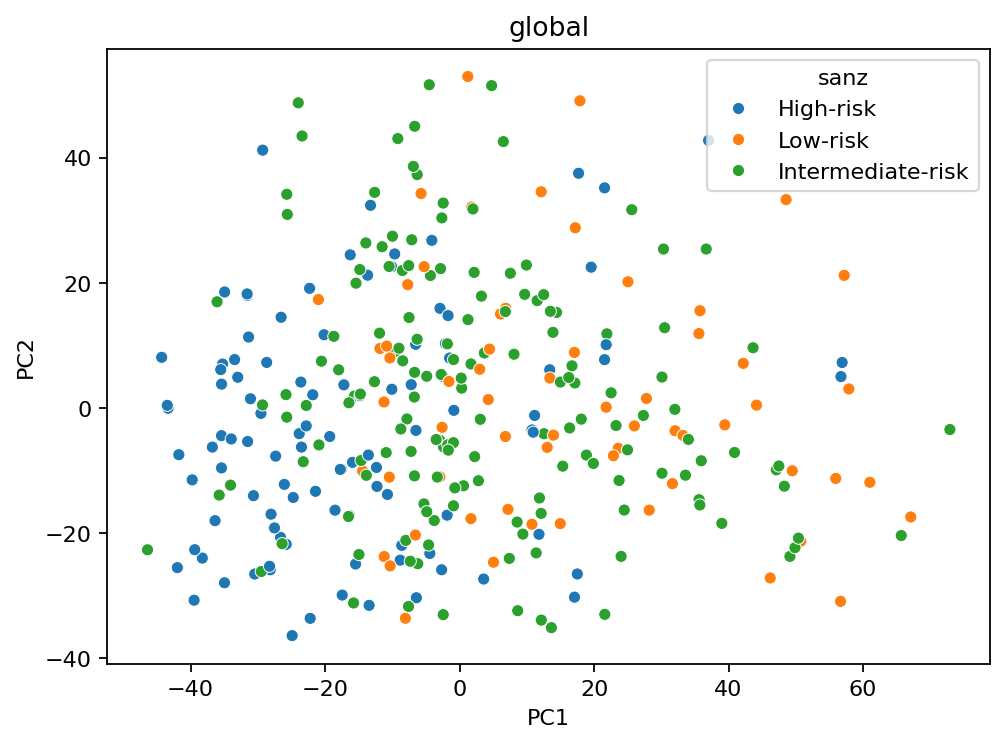

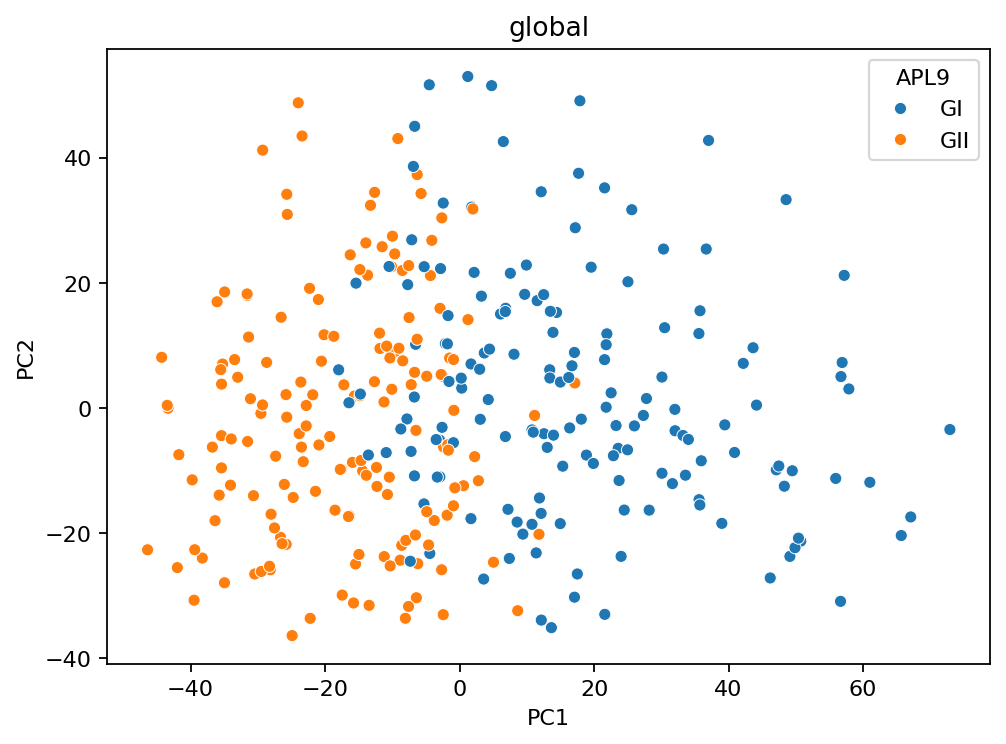

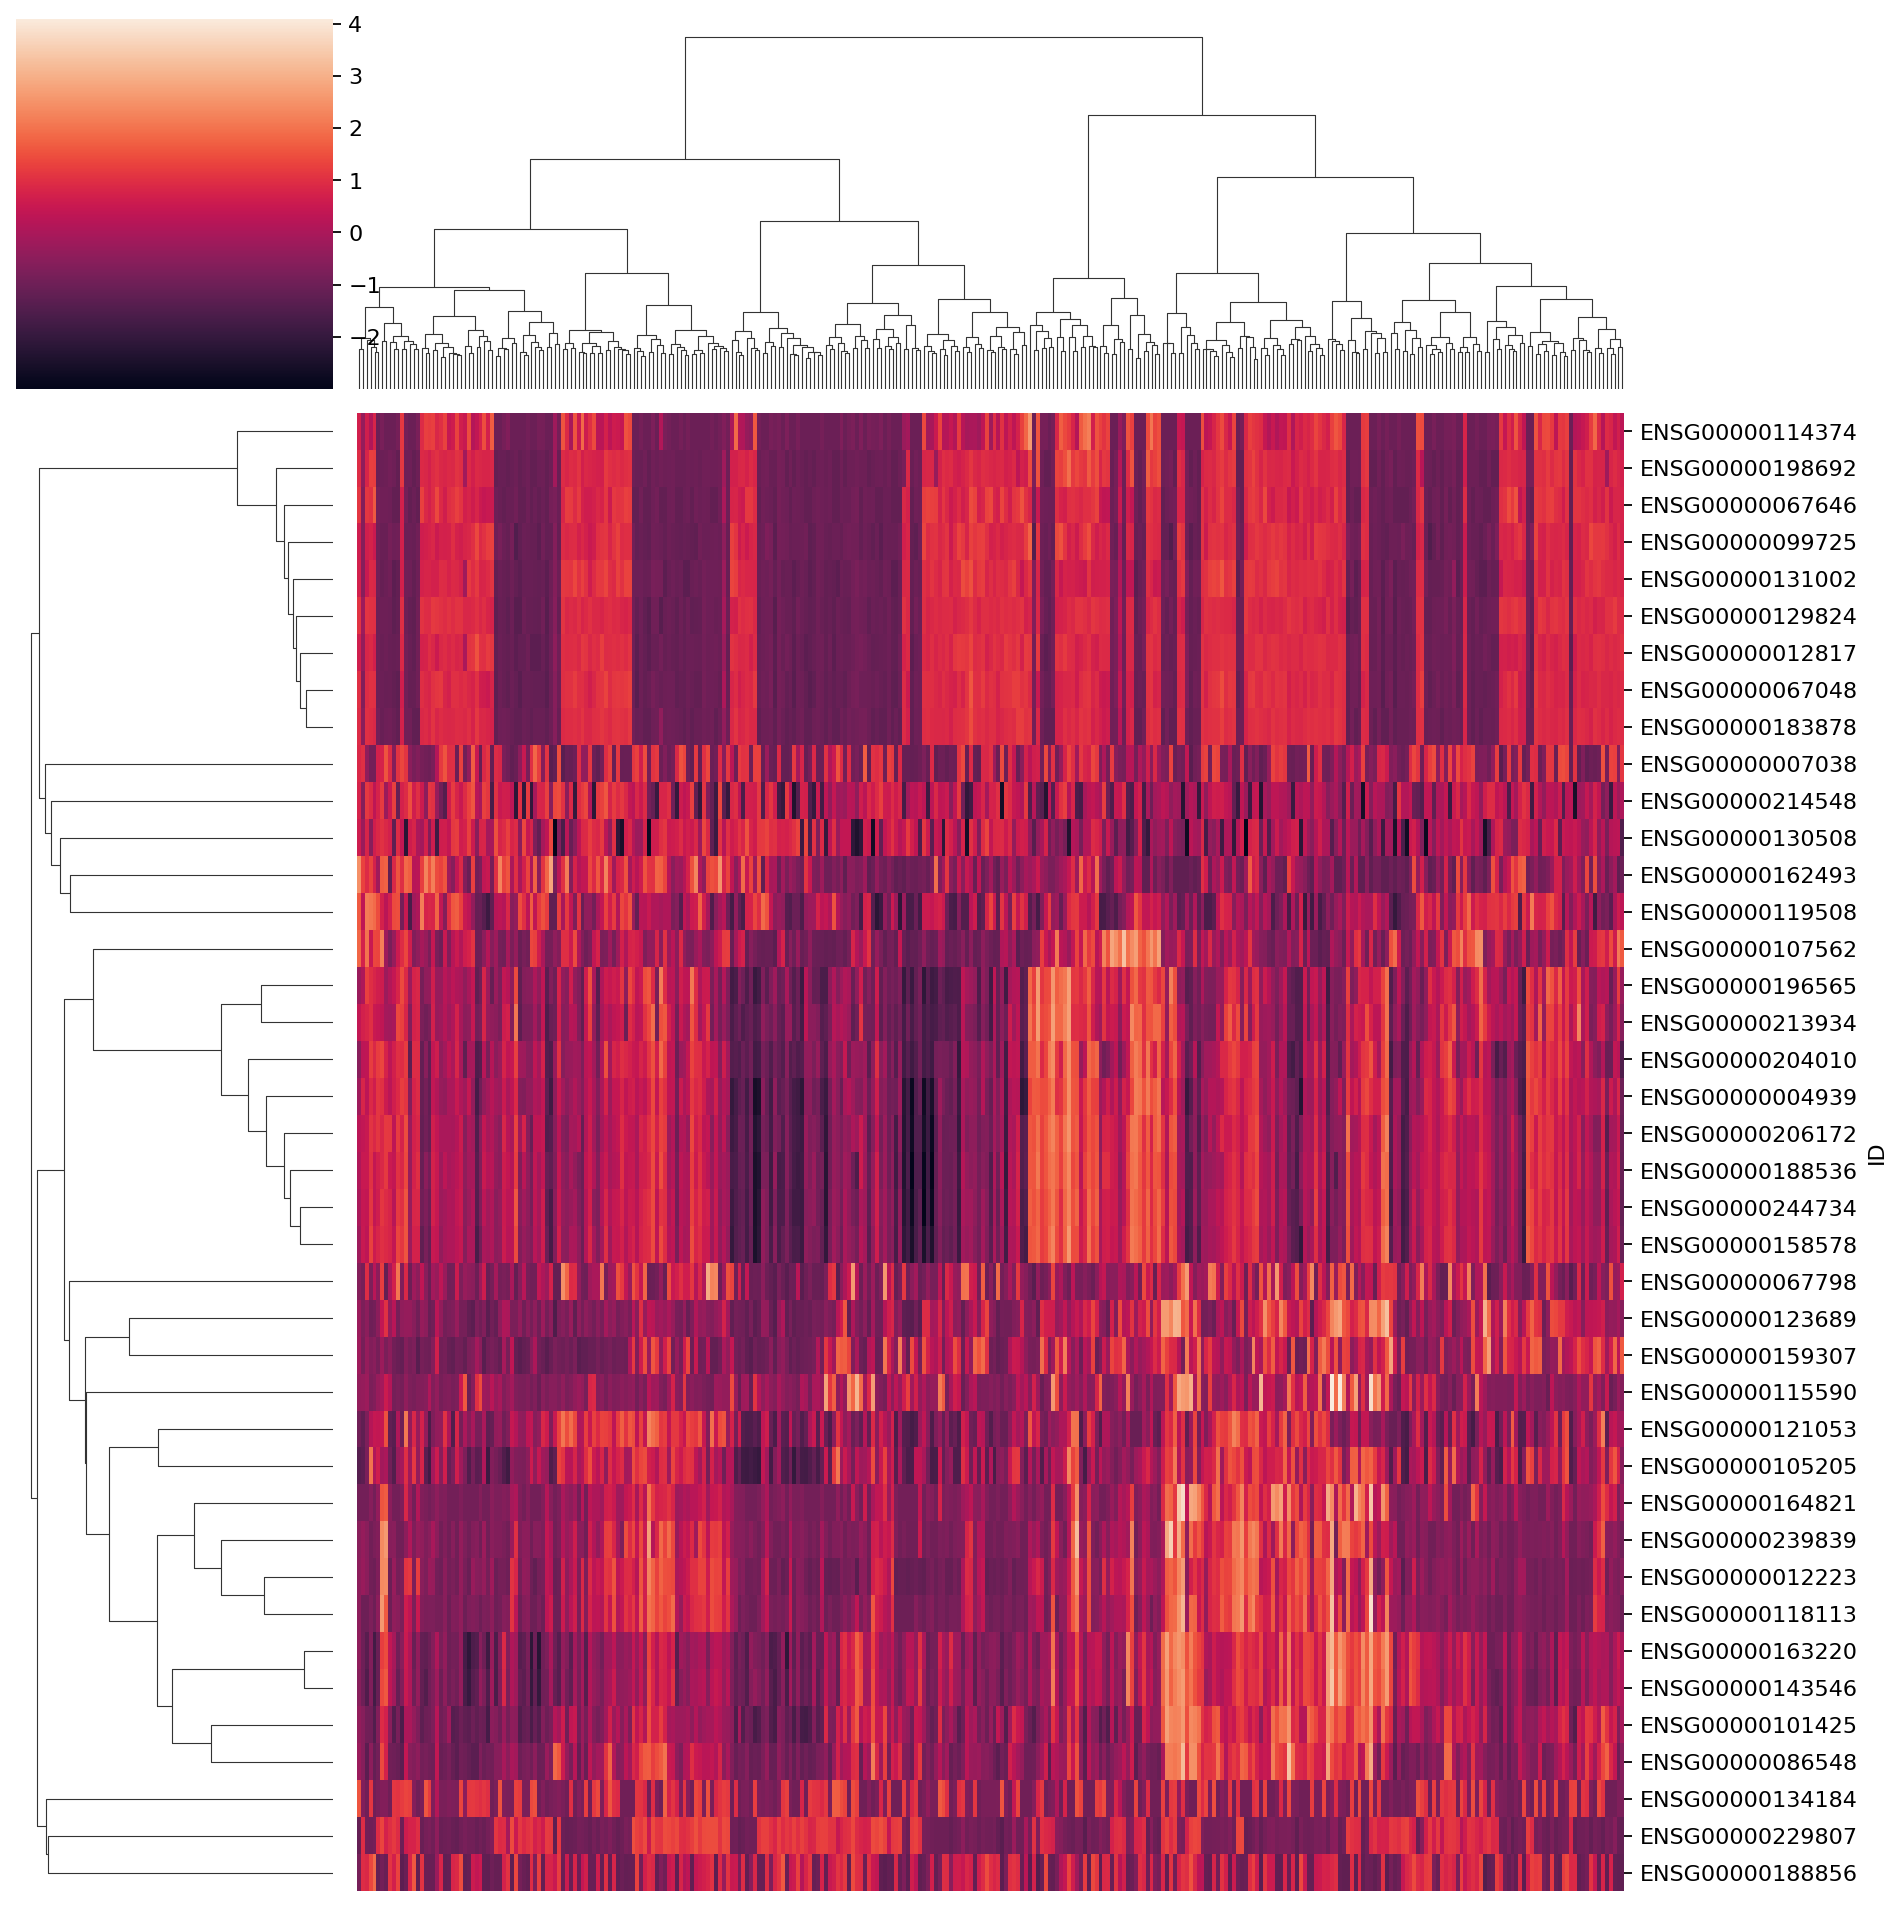

In [12]:
for name in ['idade_histograma','idade_sanz','matriz_ausencia','completude','sanz_APL9','candidatos_APL9','vst_global_histograma','pca_global_sanz_PC2','pca_global_APL9_PC2','heatmap_global_40genes']:
    display(Image(filename=str(ROOT/'figuras'/f'{name}.png')))

# Auditoria da união das partes VST

As partes foram lidas como arquivos gzip independentes e unidas na sequência 01 → 02 → 03 → 04, sem ordenação dos genes. O cabeçalho das quatro partes é idêntico byte a byte: foi escrito uma vez, e as outras três ocorrências foram registradas e omitidas. `ID` continua sendo a coluna de identificadores dos genes.

| Parte | Genes | Primeiro ID | Último ID |
| --- | ---: | --- | --- |
| GSE172057_VST_parte_01.txt.gz | 10,000 | ENSG00000000003 | ENSG00000159917 |
| GSE172057_VST_parte_02.txt.gz | 10,000 | ENSG00000159921 | ENSG00000219395 |
| GSE172057_VST_parte_03.txt.gz | 10,000 | ENSG00000219409 | ENSG00000255362 |
| GSE172057_VST_parte_04.txt.gz | 6,119 | ENSG00000255363 | ENSG00000273493 |

Resultado: **36,119 genes × 323 amostras**, além da coluna `ID`. Há 36,119 identificadores de genes únicos; nenhum ID de gene foi removido, agregado ou reordenado. As colunas de amostras começam em APL2 e terminam em APL379, preservando todos os intervalos e a ordem recebida. APL320 e APL321 são colunas separadas nestas partes. Isso descreve os arquivos recebidos agora, sem estabelecer o formato do arquivo integral inacessível enviado anteriormente.

Todos os registros têm 324 campos separados por tabulação. O CRC gzip das quatro partes e da saída foi verificado pela leitura completa. As linhas de dados foram copiadas como bytes, sem conversão ou arredondamento de números. Uma segunda leitura confirmou que o conteúdo descompactado é idêntico ao cabeçalho único seguido dos quatro blocos originais, e que a sequência de IDs foi preservada.

- SHA-256 do conteúdo descompactado: `0032c4f8beab4dead030512beb1ca7966c9902bc0e88ac54e25dc448db489627`.
- SHA-256 da sequência de IDs: `679f2d145d27813aa4e9efa484614a537c33aed7848cddf8d7c1570030011726`.
- SHA-256 do gzip de saída: `1328d23813e337239c675e9c5a01fd67bc69a54179145e06368ca191ff6bb86e`.

Saída: `dados_processados/GSE172057_VST_unificada.txt.gz`. Os quatro arquivos recebidos foram preservados em `dados_originais/` com permissão somente leitura. A saída também foi marcada somente leitura. Os checksums individuais, limites de cada bloco e decisões constam em `auditoria_uniao_partes.json`.

Não é possível comprovar equivalência com o arquivo integral anterior sem acesso a esse arquivo ou ao seu checksum descompactado. A ausência de genes ou amostras em relação ao estudo original precisa de evidência externa; a união garante preservação integral destas quatro partes.

Para reproduzir a união em outro caminho (o script recusa sobrescrever saída existente):

```bash
python scripts/merge_vst_parts.py --parts dados_originais/GSE172057_VST_parte_01.txt.gz dados_originais/GSE172057_VST_parte_02.txt.gz dados_originais/GSE172057_VST_parte_03.txt.gz dados_originais/GSE172057_VST_parte_04.txt.gz --output dados_processados/uniao_reproduzida.txt.gz --audit relatorios/auditoria_reproduzida.json
```


## Relatório acadêmico com resultados reais

In [13]:
display(Markdown((ROOT/'relatorios/EDA.md').read_text()))

# EDA de LPA — resultados observados

Processamento UTC: 2026-10-27T23:43:52.957935+00:00. Originais preservados; nenhuma imputação, modelo preditivo ou exclusão de pacientes por qualidade. Consulte `auditoria_uniao_partes.md` para a reconstrução exata da matriz.

## Coorte clínica
A Tabela S22 contém **346 pacientes**, e a S5 contém **323 registros RNA-seq**, todos com correspondência na S22 após remoção apenas dos sufixos A/C/AC documentados na nota †. IDs originais foram conservados. A S22 inclui 23 pacientes sem registro S5; não se presume presença na VST.
Sanz na S22: {'Intermediate-risk': 172, 'High-risk': 109, 'Low-risk': 65}. Mediana de idade: 38.0 anos. APL9: {'GII': 163, 'GI': 160}, com 23 ausências.
A nota § menciona n=321 com sobrevida, mas há 323 rótulos APL9 observados na tabela: não se deve converter a nota em filtro nem presumir eventos/datas disponíveis.

As contagens WBC e plaquetas só estão disponíveis como categorias. O limiar de plaquetas do suplemento é ≥40, enquanto a definição de Sanz do artigo usa >40. Os grupos originais foram preservados; a reconstrução categórica sinalizou 0 inconsistências nos testes implementados.
Zero mutacional indica resultado negativo observado, não ausência de dado. Não houve imputação. Tabelas de completude, padrões de ausência e estatísticas por grupo estão em `tabelas/`.

## Mortalidade precoce candidata
Há **22 pacientes sem registro de consolidação**, classificados exclusivamente como `early_death_candidate`: {'GII': 17, 'GI': 5}. Todos os 22 constam na S5.
O artigo relata 22 mortes durante indução e dois perdidos de seguimento entre 348 pacientes. A S22 tem 346 registros; a concordância agregada não confirma identidade dos óbitos. Ausência de consolidação também pode refletir omissão, não realização, recusa ou outras circunstâncias não documentadas. False significa somente consolidação registrada.

**22 dos 22 candidatos possuem ID inequívoco na VST**. Isso confirma a correspondência das amostras, não o desfecho.

## Auditoria estrutural e integração
A matriz conjunta tem **36,119 genes × 323 amostras**. Orientação: genes nas linhas. `ID` é a coluna dos genes; a primeira amostra é APL2. Nas quatro partes recebidas, APL320 e APL321 são cabeçalhos separados, sem ambiguidade estrutural. Não houve renomeação de amostras nem correção de valores.
A verificação numérica identificou **0 valores ausentes/não numéricos/infinitos**; IDs duplicados foram bloqueados pelo leitor e não foram encontrados. Há 323 correspondências VST–S22 e 0 amostras VST sem clínica. A tabela individual de correspondência inclui também todos os pacientes sem expressão, sem exclusão silenciosa.
O SHA-256 das linhas descompactadas e o hash da sequência de genes confirmam a preservação byte a byte na união 01–04. Os três cabeçalhos redundantes foram omitidos após verificação de identidade. As partes e o arquivo unificado permanecem somente leitura.
O arquivo exportado `expressao_vst.tsv.gz` teve round-trip numérico verificado. A matriz principal unificada conserva inclusive a representação textual dos valores. A equivalência com o anexo integral anterior e com uma segunda versão transposta não foi verificada: essas fontes continuam indisponíveis.

## Distribuição e variabilidade VST
O mínimo observado é **3.44844073036933**; 24.29% das células estão a até 1e-4 desse mínimo. Isso descreve o piso numérico da transformação, sem significar ausência de transcrição ou zero bruto.
Há 0 genes de variância nula e 0 abaixo do limiar computacional 1e-8 (incluindo os de variância nula). Foram sinalizadas 0 linhas gênicas pertencentes a conjuntos de perfis numericamente idênticos e 0 colunas de amostras com perfil idêntico. Essas contagens incluem todos os membros dos conjuntos, não somente repetições adicionais. Nenhum foi removido.
As medianas de expressão por amostra variam de 4.2661 a 5.7660. 244 genes têm pelo menos 90% das amostras próximas ao piso. As tabelas apresentam médias, medianas, IQR, variância, desvio e genes mais variáveis, sem inferência prognóstica.

## PCA, agrupamentos e assinaturas
A PCA global usa até 1.000 genes com maior variância acima de 1e-8, centrados e sem padronização por desvio-padrão. A fração de variância explicada por PC1, PC2 e PC3 é, respectivamente, 20.85%, 13.03% e 6.92%. Isso mede a variância no subconjunto selecionado, não em todos os genes.
Foram produzidos escores, loadings, scree plot e projeções separadas por Sanz, GI/GII, NRAS, FLT3, sexo e candidatos inferidos. Ward/euclidiana e heatmaps usam o mesmo subconjunto; expressão padronizada é mostrada para os 40 genes mais variáveis. O critério exploratório de distância à mediana superior a 6 MAD nas componentes sinalizou 2 amostras; ele não é diagnóstico de erro e nenhuma foi excluída.
Resumos das componentes por grupos estão disponíveis. Diferenças entre médias ou agrupamentos visuais não demonstram separação clínica validada, causalidade ou valor incremental. Sem informação de lote, não é possível decompor variação biológica e técnica adequadamente.
Dos 389 IDs da assinatura publicada S16, 389 foram encontrados. 9 genes APL9 foram identificados pela correspondência documentada Ensembl–símbolo da S16, sem substituir a anotação global solicitada. Suas distribuições por grupos e coexpressão foram visualizadas; não se recalculou o escore publicado usando coeficientes sobre uma escala sem compatibilidade estabelecida. Os 389 genes foram previamente selecionados por grupos clínicos e não constituem seleção independente de Sanz.

## Anotação e limitações
R/biomaRt ainda não foi executado: R está ausente e a máquina não oferece instalação administrativa. Não foram inventados símbolos nem biotipos. A composição global de protein-coding, lncRNAs e demais classes, a tabela completa de anotação e as PCAs por biotipo permanecem pendentes. O script R conserva não mapeados, um-para-muitos e cache; é necessário confirmar o release e a montagem do estudo nos métodos suplementares. Usar um release contemporâneo não comprova compatibilidade.
Sem FASTQ e contagens brutas, a EDA VST não permite auditar qualidade das bases, cobertura ou alinhamento diretamente, nem usar DESeq2 como se fossem contagens. As métricas S5 foram preservadas como evidência documental independente.
Os testes clínicos são exploratórios: Fisher em 2×2, qui-quadrado nos demais, tamanho de efeito Cramér V e FDR BH na família declarada. Células esparsas limitam aproximações assintóticas. PCA–idade usa Spearman e BH em sua família. Nenhum desses resultados valida prognóstico.

## Implicações para modelagem posterior
É indispensável validar os eventos individuais com os autores, incluindo datas e momento da coleta. Consolidação ocorre após o diagnóstico e não deve ser preditor basal. Cerca de 22 eventos potenciais e milhares de genes tornam a seleção adaptativa muito instável: considerar assinaturas parcimoniosas, com seleção, imputação, escala e redução dimensional reaprendidas no treinamento de cada partição. Comparar futuramente clínico/Sanz, clínico+APL9 e clínico+assinatura somente com validação interna apropriada e externa. APL9 foi desenvolvida nesta coorte, o que limita a independência de uma avaliação interna posterior.
Relatar ROC-AUC, PR-AUC com referência de prevalência, calibração e incerteza na fase posterior. Reproduzir Sanz não equivale a predizer morte precoce. Não houve treino ou avaliação de modelos nem seleção definitiva de genes pelo desfecho nesta EDA.

## Referências
Ver fundamentacao.md. Lin et al. (2021), DOI 10.1158/1078-0432.CCR-20-4375, foi inspecionado no PDF fornecido. Jin et al. (2024) não foi identificado de forma inequívoca: requer título/DOI/PDF. O guia Biaggi foi indicado pelo usuário, mas seu conteúdo integral não foi consultado. Não se atribuíram resultados não verificados a essas fontes.


## Código modular completo

As próximas células definem os módulos equivalentes. Não executam chamadas de rede ou análise de expressão automaticamente. Para reproduzir: `python scripts/run.py`; para VST real, acrescentar `--matrix CAMINHO`.

### common.py

In [14]:
"""Persistência e gráficos determinísticos; não modifica os dados originais."""
from pathlib import Path
import hashlib, json
import os
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'logs/cache/matplotlib'))
os.environ.setdefault('XDG_CACHE_HOME',str(ROOT/'logs/cache'))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
ROOT = ROOT
SEED = 172057

def table(df, name):
    df.to_csv(ROOT/'tabelas'/f'{name}.csv', index=False)

def figure(name):
    plt.tight_layout()
    plt.savefig(ROOT/'figuras'/f'{name}.png', dpi=160, bbox_inches='tight')
    plt.close('all')

def checksum(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)
    return h.hexdigest()

def write_json(path, obj):
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str))


### clinical.py

In [15]:
"""Auditoria clínica: conserva IDs originais e só normaliza sufixos documentados."""
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact
from statsmodels.stats.multitest import multipletests
from common import ROOT, table, figure

COLS=['original_s22','sex','age','sanz','consolidation','wbc_gt10','platelets_ge40','FLT3_ITD','FLT3_TKD','WT1','NRAS','ARID1A','RREB1','KRAS','EBF3','PML_RARA','APL9']

def run():
    path=ROOT/'dados_originais/suplemento_lin_2021.xlsx'
    x=pd.ExcelFile(path)
    table(pd.DataFrame([{'sheet':s,'rows_including_title':pd.read_excel(x,s,header=None).shape[0], 'columns':pd.read_excel(x,s,header=None).shape[1]} for s in x.sheet_names]),'excel_sheets')
    raw=pd.read_excel(x,'Table S22',header=None)
    table(raw.head(8),'s22_primeiras_linhas');table(raw.tail(8),'s22_ultimas_linhas')
    # A primeira linha é título, a segunda cabeçalho; seleção explícita de pacientes.
    body=raw.iloc[2:].copy()
    keep=body.iloc[:,0].astype(str).str.fullmatch(r'APL\d+(?:AC|A|C)?')
    removed=body.loc[~keep].copy();removed['reason']='linha vazia ou nota; não é paciente'
    table(removed,'s22_linhas_nao_pacientes')
    d=body.loc[keep].copy();d.columns=COLS
    d.insert(1,'patient_id',d.original_s22.str.replace(r'(AC|A|C)$','',regex=True))
    if d.patient_id.duplicated().any(): raise ValueError('IDs S22 normalizados duplicados: revisão necessária')
    for c in ['age',*COLS[5:15]]: d[c]=pd.to_numeric(d[c],errors='raise')
    # Não é desfecho confirmado; False significa apenas consolidação registrada.
    d['early_death_candidate']=d.consolidation.isna()
    d['sanz_binary']=d.sanz.map({'High-risk':'HR','Low-risk':'não HR','Intermediate-risk':'não HR'})
    s5=pd.read_excel(x,'Table S5',header=1)
    table(s5,'s5_preservada')
    s5ids=s5.iloc[:,1].astype(str)
    if s5ids.duplicated().any(): raise ValueError('IDs S5 duplicados')
    all_ids=sorted(set(s5ids)|set(d.patient_id),key=lambda s:int(s[3:]))
    mapping=pd.DataFrame({'patient_id':all_ids}).merge(d[['patient_id','original_s22']],how='left').merge(pd.DataFrame({'patient_id':s5ids,'original_s5':s5ids}),how='left')
    mapping['original_vst']=pd.NA
    mapping['status']=np.where(mapping.original_s5.notna() & mapping.original_s22.notna(),'S5–S22 confirmada; VST pendente','presença em somente uma tabela; VST pendente')
    mapping['rule']='remoção apenas do sufixo A/C/AC de S22; igualdade exata do ID restante'
    mapping['evidence']='nota † da Tabela S22'
    mapping['ambiguity']='arquivo VST indisponível para auditoria'
    table(mapping,'correspondencia_ids')
    table(d,'clinica_completa');d.to_csv(ROOT/'dados_processados/clinica.csv',index=False)
    completeness=pd.DataFrame({'variable':COLS[1:],'observed':[d[c].notna().sum() for c in COLS[1:]],'missing':[d[c].isna().sum() for c in COLS[1:]],'missing_fraction':[d[c].isna().mean() for c in COLS[1:]]})
    table(completeness,'completude_clinica')
    table(pd.DataFrame({'patient_id':d.patient_id,'missing':d[COLS[1:]].isna().sum(axis=1)}),'ausencia_por_paciente')
    patterns=d[COLS[1:]].isna().astype(int).astype(str).agg(''.join,axis=1).value_counts().rename_axis('pattern_1_missing').reset_index(name='n')
    table(patterns,'padroes_ausencia')
    numeric=d.age.describe(percentiles=[.25,.5,.75]).to_frame().T
    numeric['missing']=d.age.isna().sum();numeric['IQR']=numeric['75%']-numeric['25%'];table(numeric.reset_index(names='variable'),'idade_descritiva')
    rows=[]
    categorical=[c for c in COLS[1:] if c!='age']+['sanz_binary','early_death_candidate']
    for c in categorical:
        for level,n in d[c].fillna('Ausente').value_counts(dropna=False).items():
            rows.append({'variable':c,'level':level,'n':n,'percent_total':100*n/len(d),'denominator':len(d)})
    table(pd.DataFrame(rows),'tabela1_categoricas')
    for group in ['sanz','APL9','early_death_candidate']:
        table(d.groupby(group,dropna=False).age.describe().reset_index(),f'idade_por_{group}')
        for c in categorical:
            if c!=group: table(pd.crosstab(d[c].fillna('Ausente'),d[group].fillna('Ausente')).reset_index(),f'contingencia_{c}_{group}')
    candidates=d[d.early_death_candidate]
    table(candidates,'mortalidade_candidatos_nao_confirmados')
    table(candidates[['patient_id','original_s22','sanz','APL9']].merge(pd.DataFrame({'patient_id':s5ids,'s5_present':True}),how='left'),'candidatos_correspondencia_s5')
    # Discordâncias são sinalizadas, não corrigidas: ≥40 na planilha versus >40 na definição.
    issues=[]
    for _,r in d.iterrows():
        expected='High-risk' if r.wbc_gt10==1 else ('Low-risk' if r.platelets_ge40==1 else 'Intermediate-risk')
        if r.sanz!=expected: issues.append({'patient_id':r.patient_id,'issue':'Sanz difere da reconstrução categórica; investigar limiar de 40','observed':r.sanz,'reconstruction':expected})
        if not 0<=r.age<=120: issues.append({'patient_id':r.patient_id,'issue':'idade implausível'})
        for c in COLS[5:15]:
            if pd.notna(r[c]) and r[c] not in [0,1]: issues.append({'patient_id':r.patient_id,'issue':f'código inesperado {c}: {r[c]}'})
    table(pd.DataFrame(issues,columns=['patient_id','issue','observed','reconstruction']),'consistencia_clinica')
    # Testes exploratórios com tamanhos de efeito; não constituem prognóstico.
    tests=[]
    for c in ['sanz','FLT3_ITD','FLT3_TKD','WT1','NRAS','ARID1A','RREB1','KRAS','EBF3','sex']:
        ct=pd.crosstab(d[c],d.APL9)
        chi,p,_,exp=chi2_contingency(ct)
        method='chi-quadrado';effect=(chi/(ct.to_numpy().sum()*min(ct.shape[0]-1,ct.shape[1]-1)))**.5
        if ct.shape==(2,2): _,p=fisher_exact(ct);method='Fisher bilateral'
        tests.append({'variable':c,'n_complete':int(ct.to_numpy().sum()),'test':method,'p':p,'cramers_v':effect,'min_expected':float(exp.min())})
    tests=pd.DataFrame(tests);tests['q_BH']=multipletests(tests.p,method='fdr_bh')[1];table(tests,'associacoes_APL9_exploratorias')
    # Figuras com denominadores explícitos; dados ausentes aparecem como categoria.
    sns.heatmap(d[COLS[1:]].isna(),cbar=False);plt.ylabel('Pacientes S22');figure('matriz_ausencia')
    completeness.set_index('variable').missing_fraction.plot.barh();plt.xlabel('Proporção ausente');figure('completude')
    d.age.plot.hist(bins=20);plt.xlabel('Idade (anos)');figure('idade_histograma')
    sns.boxplot(data=d,x='sanz',y='age');figure('idade_sanz')
    for c in ['sanz','APL9','sex','consolidation']:
        d[c].fillna('Ausente').value_counts().plot.bar();plt.ylabel(f'Pacientes (N={len(d)})');figure('distribuicao_'+c)
    ct=pd.crosstab(d.sanz,d.APL9);ct.div(ct.sum(axis=1),axis=0).plot.bar(stacked=True);plt.ylabel('Proporção entre APL9 observados');figure('sanz_APL9')
    pd.crosstab(d.sanz,d.early_death_candidate).plot.bar(stacked=True);plt.ylabel('Pacientes; candidato ≠ morte confirmada');figure('candidatos_sanz')
    sns.heatmap(pd.crosstab(d.APL9,d.early_death_candidate),annot=True,fmt='d');figure('candidatos_APL9')
    table(pd.read_excel(x,'Table S16',header=1),'assinatura_389_publicada')
    for c in ['PML_RARA','APL9']:
        table(pd.crosstab(d.sanz,d[c].isna()).reset_index(),f'ausencia_{c}_sanz')
    summary={'s22_patients':len(d),'s5_samples':len(s5ids),'s5_s22_matches':len(set(s5ids)&set(d.patient_id)), 'clinical_without_s5':sorted(set(d.patient_id)-set(s5ids)), 'candidate_count':len(candidates),'candidate_APL9':candidates.APL9.value_counts().to_dict(),'candidates_in_s5':int(candidates.patient_id.isin(s5ids).sum()),'sanz':d.sanz.value_counts().to_dict(),'APL9':d.APL9.value_counts().to_dict(),'APL9_missing':int(d.APL9.isna().sum()),'sanz_categorical_discrepancies':len(issues),'age_median':float(d.age.median())}
    return d,s5,summary


### expression.py

In [16]:
"""Leitura estrita: recusa cabeçalhos ambíguos em vez de inventar amostras."""
import csv, gzip, re, json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from statsmodels.stats.multitest import multipletests
from common import ROOT, SEED, table, figure, checksum

def read_matrix(path):
    op=gzip.open if str(path).endswith('.gz') else open
    with op(path,'rt',encoding='utf-8-sig',newline='') as f:
        sample=f.read(65536)
    # Testa somente separadores explícitos; espaços não são divididos implicitamente.
    candidates={sep:len(next(csv.reader(sample.splitlines(),delimiter=sep))) for sep in ['\t',',',';']}
    sep=max(candidates,key=candidates.get)
    if candidates[sep]<2: raise ValueError('Separador não identificável sem ambiguidade')
    widths=Counter();bad=[]
    with op(path,'rt',encoding='utf-8-sig',newline='') as f:
        reader=csv.reader(f,delimiter=sep);header=next(reader)
        for line,row in enumerate(reader,2):
            widths[len(row)]+=1
            if len(row)!=len(header): bad.append({'line':line,'fields':len(row),'expected':len(header)})
    audit={'file':str(path),'sha256':checksum(path),'delimiter':repr(sep),'header_fields':len(header),'row_widths':dict(widths),'inconsistent_rows':len(bad),'duplicate_headers':len(header)-len(set(header))}
    table(pd.DataFrame(bad,columns=['line','fields','expected']),'vst_linhas_inconsistentes')
    (ROOT/'logs/vst_estrutura.json').write_text(json.dumps(audit,indent=2))
    if bad or len(set(header))!=len(header) or any(not h.strip() for h in header): raise ValueError('Cabeçalho vazio/duplicado ou largura inconsistente; consultar logs/vst_estrutura.json')
    # Detecta o cabeçalho conhecido e qualquer célula com dois IDs APL.
    if any(len(re.findall(r'APL\d+',h))>1 for h in header): raise ValueError('Cabeçalho contém múltiplos IDs APL na mesma célula; não foi dividido')
    raw=pd.read_csv(path,sep=sep,dtype=str,keep_default_na=False,compression='infer')
    table(raw.head(5),'vst_primeiras_linhas');table(raw.tail(5),'vst_ultimas_linhas')
    ids=raw.iloc[:,0]
    gene_rows=ids.str.fullmatch(r'ENSG\d+(?:\.\d+)?').all()
    gene_cols=all(re.fullmatch(r'ENSG\d+(?:\.\d+)?',h) for h in header[1:])
    if gene_rows==gene_cols: raise ValueError('Orientação não identificada inequivocamente')
    matrix=raw.iloc[:,1:].apply(pd.to_numeric,errors='coerce');matrix.index=ids
    invalid=matrix.isna() | ~np.isfinite(matrix)
    if invalid.any().any():
        ri,ci=np.where(invalid.to_numpy());table(pd.DataFrame({'row_id':matrix.index[ri],'column':matrix.columns[ci],'raw_value':[raw.iloc[r,c+1] for r,c in zip(ri,ci)]}),'vst_valores_invalidos')
        raise ValueError(f'{invalid.to_numpy().sum()} valores ausentes/não numéricos/infinitos; nenhuma imputação aplicada')
    if gene_cols: matrix=matrix.T
    if matrix.index.duplicated().any() or matrix.columns.duplicated().any(): raise ValueError('IDs de genes/amostras duplicados: nenhuma agregação automática')
    if not all(re.fullmatch(r'APL\d+',str(c)) for c in matrix.columns): raise ValueError('IDs de amostra fora do padrão confirmado APLn; revisão necessária')
    audit.update(genes=len(matrix),samples=matrix.shape[1],orientation='genes_rows' if gene_rows else 'genes_columns',missing=0)
    return matrix,audit

def run(path,clinical,s5,second=None):
    m,audit=read_matrix(path)
    if second:
        b,_=read_matrix(second)
        same_ids=m.index.equals(b.index) and m.columns.equals(b.columns)
        audit['second_exact_ids_order_and_values']=bool(same_ids and np.array_equal(m.to_numpy(),b.to_numpy()))
        audit['second_same_id_sets']=bool(set(m.index)==set(b.index) and set(m.columns)==set(b.columns))
        if audit['second_same_id_sets']: audit['second_equal_after_explicit_reorder']=bool(np.array_equal(m.to_numpy(),b.loc[m.index,m.columns].to_numpy()))
    else: audit['second_matrix']='não fornecida; equivalência não verificada'
    # 17 dígitos significativos permitem round-trip dos floats; fontes permanecem imutáveis.
    m.to_csv(ROOT/'dados_processados/expressao_vst.tsv.gz',sep='\t',float_format='%.17g')
    restored=pd.read_csv(ROOT/'dados_processados/expressao_vst.tsv.gz',sep='\t',index_col=0,float_precision='round_trip')
    if not np.array_equal(m.to_numpy(),restored.to_numpy()): raise ValueError('Falha no round-trip da matriz exportada')
    ids=pd.DataFrame({'patient_id':sorted(set(m.columns)|set(clinical.patient_id)|set(s5.iloc[:,1]))})
    ids['original_vst']=ids.patient_id.where(ids.patient_id.isin(m.columns))
    ids=ids.merge(clinical[['patient_id','original_s22']],how='left')
    ids['original_s5']=ids.patient_id.where(ids.patient_id.isin(s5.iloc[:,1]))
    ids['status']=np.select([ids.original_vst.notna()&ids.original_s22.notna(),ids.original_vst.notna()],['VST–S22 confirmada','VST sem clínica'],default='sem expressão observada')
    ids['rule']='igualdade exata após retirada de sufixo documentado de S22';ids['evidence']='nota † S22';ids['ambiguity']=''
    table(ids,'correspondencia_ids')
    joined=m.T.join(clinical.set_index('patient_id'),how='inner')
    joined.to_csv(ROOT/'dados_processados/clinica_transcriptomica_confirmada.tsv.gz',sep='\t',float_format='%.17g')
    for label,subset in [('antes',clinical),('apos',clinical[clinical.patient_id.isin(m.columns)])]:
        for c in ['sanz','APL9']: table(subset[c].value_counts(dropna=False).rename_axis(c).reset_index(name='n'),f'grupos_{c}_{label}_integracao')
    v=m.var(axis=1);means=m.mean(axis=1);floor=float(m.min().min())
    stats=pd.DataFrame({'ensembl_id':m.index,'mean':means,'median':m.median(axis=1),'variance':v,'std':m.std(axis=1),'near_floor_fraction':np.isclose(m.to_numpy(),floor,atol=1e-4,rtol=0).mean(axis=1)})
    table(stats,'genes_estatisticas');table(stats.sort_values('variance',ascending=False).head(100),'genes_maior_variabilidade');table(stats.sort_values('near_floor_fraction',ascending=False).head(100),'genes_proximos_piso')
    ss=m.describe().T;ss['IQR']=ss['75%']-ss['25%'];table(ss.reset_index(names='patient_id'),'amostras_estatisticas')
    gene_dup=m.duplicated(keep=False);sample_dup=m.T.duplicated(keep=False)
    table(pd.DataFrame({'ensembl_id':m.index,'numerically_duplicated':gene_dup,'zero_variance':v.eq(0),'near_zero_variance':v.lt(1e-8)}),'genes_sinais_auditoria')
    table(pd.DataFrame({'patient_id':m.columns,'numerically_duplicated':sample_dup}),'amostras_sinais_auditoria')
    audit.update(zero_variance=int(v.eq(0).sum()),near_zero_variance=int(v.lt(1e-8).sum()),duplicate_gene_rows=int(gene_dup.sum()),duplicate_sample_columns=int(sample_dup.sum()),floor=floor,near_floor_fraction=float(stats.near_floor_fraction.mean()),candidates_with_expression=int(clinical[clinical.early_death_candidate].patient_id.isin(m.columns).sum()))
    vals=m.to_numpy().ravel();rng=np.random.default_rng(SEED)
    sampled=rng.choice(vals,min(len(vals),100000),replace=False)
    plt.hist(vals,bins=100);plt.xlabel('VST');figure('vst_global_histograma')
    sns.kdeplot(sampled);plt.xlabel('VST; KDE amostra fixa de até 100 mil células');figure('vst_global_densidade')
    for c in m.columns[:4]: sns.histplot(m[c],bins=60,label=c,element='step',fill=False)
    plt.legend();figure('vst_amostras_selecionadas')
    plt.figure(figsize=(18,5));plt.boxplot(m.to_numpy(),showfliers=False);plt.xlabel('Amostra na ordem original');plt.ylabel('VST');figure('vst_boxplot_amostras')
    plt.scatter(means,v,s=2,alpha=.25);plt.xlabel('Média VST');plt.ylabel('Variância');figure('media_variancia')
    annpath=ROOT/'anotacoes/biomart.csv'
    annotation=None
    if annpath.exists():
        annotation=pd.read_csv(annpath,dtype={'ensembl_gene_id':str})
        table(annotation,'anotacao_completa')
        # Um-para-muitos é auditado antes de qualquer seleção de subconjunto.
        table(annotation[annotation.ensembl_gene_id.duplicated(keep=False)],'anotacao_um_para_muitos')
        groups=annotation.groupby('ensembl_gene_id').gene_biotype.agg(lambda x:';'.join(sorted(set(x.dropna()))))
        counts=groups.value_counts().rename_axis('biotype').reset_index(name='n');counts['fraction']=counts.n/counts.n.sum();table(counts,'biotipos')
        counts.set_index('biotype').n.plot.barh(figsize=(9,8));figure('biotipos')
    subsets={'global':m.index}
    if annotation is not None:
        for name in ['protein_coding','lncRNA']:
            eligible=set(annotation.loc[annotation.gene_biotype.eq(name),'ensembl_gene_id'])
            subsets[name]=[g for g in m.index if re.sub(r'\.\d+$','',g) in eligible]
    clinical_index=clinical.set_index('patient_id').reindex(m.columns)
    for subset,genes in subsets.items():
        usable=v.reindex(genes);usable=usable[usable>1e-8].nlargest(1000).index
        k=min(10,len(usable),m.shape[1]-1)
        if k<3: continue
        # PCA centrada, sem dividir pelo desvio: VST já estabiliza a variância.
        model=PCA(n_components=k,svd_solver='full');scores=model.fit_transform(m.loc[usable].T)
        pcs=pd.DataFrame(scores,index=m.columns,columns=[f'PC{i+1}' for i in range(k)])
        table(pcs.reset_index(names='patient_id'),f'pca_{subset}_scores')
        table(pd.DataFrame({'component':pcs.columns,'variance_ratio':model.explained_variance_ratio_}),f'pca_{subset}_variance')
        table(pd.DataFrame(model.components_.T,index=usable,columns=pcs.columns).reset_index(names='ensembl_id'),f'pca_{subset}_loadings')
        plt.plot(range(1,k+1),model.explained_variance_ratio_,'o-');plt.ylabel('Fração da variância');figure(f'pca_{subset}_scree')
        clinical_index['FLT3_any']=clinical_index[['FLT3_ITD','FLT3_TKD']].max(axis=1)
        for c in ['sanz','APL9','NRAS','FLT3_any','sex','early_death_candidate']:
            for pc in ['PC2','PC3']:
                plot=pcs.join(clinical_index[[c]]);plot[c]=plot[c].astype('string').fillna('Sem metadado')
                sns.scatterplot(data=plot,x='PC1',y=pc,hue=c,s=30);plt.title(subset+(' — rótulo inferido' if c=='early_death_candidate' else ''));figure(f'pca_{subset}_{c}_{pc}')
        robust=(pcs-pcs.median()).abs().div((pcs-pcs.median()).abs().median().replace(0,np.nan))
        table(pd.DataFrame({'patient_id':pcs.index,'max_pc_mad_ratio':robust.max(axis=1),'flag_gt6':robust.max(axis=1)>6,'action':'sinalização somente; não excluir'}),f'outliers_{subset}')
        distance=squareform(pdist(m.loc[usable].T,metric='euclidean'))
        tree=linkage(m.loc[usable].T,method='ward')
        sns.clustermap(pd.DataFrame(distance,index=m.columns,columns=m.columns),row_linkage=tree,col_linkage=tree,xticklabels=False,yticklabels=False);figure(f'distancias_{subset}')
        top=usable[:40];z=m.loc[top].sub(m.loc[top].mean(axis=1),axis=0).div(m.loc[top].std(axis=1),axis=0)
        sns.clustermap(z,col_linkage=tree,xticklabels=False,yticklabels=True,figsize=(12,12));figure(f'heatmap_{subset}_40genes')
        tests=[]
        for pc in pcs.columns[:3]:
            ok=clinical_index.age.notna();rho,p=spearmanr(pcs.loc[ok,pc],clinical_index.loc[ok,'age']);tests.append({'component':pc,'variable':'age','rho':rho,'p':p})
        t=pd.DataFrame(tests);t['q_BH']=multipletests(t.p,method='fdr_bh')[1];table(t,f'pca_{subset}_clinica_exploratoria')
    # Assinaturas publicadas: Ensembl diretamente de S16; não seleção independente.
    sig=pd.read_csv(ROOT/'tabelas/assinatura_389_publicada.csv');sigids=sig.iloc[:,0].astype(str)
    common=m.index.intersection(sigids)
    table(pd.DataFrame({'ensembl_id':sigids,'present':sigids.isin(m.index)}),'assinatura_389_disponibilidade')
    if len(common)>=2:
        selected=m.loc[common].var(axis=1).nlargest(30).index
        sns.heatmap(m.loc[selected].T.corr(),vmin=-1,vmax=1,cmap='vlag');figure('coexpressao_30genes_publicados')
    apl9=sig[sig['Gene Symbol'].isin(['GATA1','CLCN4','CACNA2D2','OPTN','KRT1','LTF','S100A12','LEF1','LGALS1'])]
    table(apl9,'APL9_ids_fonte_S16')
    for _,row in apl9.iterrows():
        gene=row.iloc[0]
        if gene in m.index:
            plot=clinical_index.copy();plot['VST']=m.loc[gene].values
            for c in ['sanz','APL9','early_death_candidate']:
                sns.boxplot(data=plot,x=c,y='VST');plt.title(str(row['Gene Symbol'])+'; descrição exploratória');figure(f'APL9_{row["Gene Symbol"]}_{c}')
    table(pd.DataFrame([audit]),'auditoria_expressao')
    return audit


### Script R biomaRt

```r
#!/usr/bin/env Rscript
# Uso: Rscript scripts/annotate_biomart.R dados_processados/gene_ids.txt 103
# Release explícito: 103 é contemporâneo a 2021, NÃO confirmação do estudo.
args <- commandArgs(trailingOnly=TRUE)
if (length(args)!=2) stop('Forneça arquivo com IDs e release Ensembl investigado')
if (!requireNamespace('biomaRt', quietly=TRUE)) stop('Instale BiocManager e biomaRt; consultar README')
ids_original <- readLines(args[1]); ids <- unique(sub('\\.[0-9]+$', '', ids_original))
release <- as.integer(args[2]); dir.create('anotacoes', showWarnings=FALSE)
keyfile <- tempfile(); writeLines(sort(ids), keyfile)
key <- unname(tools::md5sum(keyfile)); unlink(keyfile)
cache <- sprintf('anotacoes/cache_release%s_%s.rds',release,key)
if (file.exists(cache)) {
  result <- readRDS(cache)
} else {
  mart <- biomaRt::useEnsembl(biomart='genes',dataset='hsapiens_gene_ensembl',version=release)
  attrs <- c('ensembl_gene_id','external_gene_name','gene_biotype','description','chromosome_name','start_position','end_position','strand')
  pieces <- split(ids, ceiling(seq_along(ids)/500))
  result <- do.call(rbind,lapply(pieces,function(chunk) biomaRt::getBM(attributes=attrs,filters='ensembl_gene_id',values=chunk,mart=mart)))
  result$ensembl_release <- release
  datasets <- biomaRt::listDatasets(mart)
  result$genome_assembly <- datasets$version[match('hsapiens_gene_ensembl',datasets$dataset)]
  saveRDS(result,cache)
}
# Left join preserva não mapeados e relações um-para-muitos, sem escolher símbolos.
full <- merge(data.frame(original_ensembl_id=ids_original,ensembl_gene_id=sub('\\.[0-9]+$','',ids_original)),result,by='ensembl_gene_id',all.x=TRUE,sort=FALSE)
full$mapping_status <- ifelse(is.na(full$gene_biotype),'unmapped_or_missing_biotype','mapped')
write.csv(full,'anotacoes/biomart.csv',row.names=FALSE,na='')
writeLines(c(paste('Processed UTC:',format(Sys.time(),tz='UTC')),paste('Ensembl release:',release),'Compatibilidade com anotação original: ainda não confirmada; verificar métodos suplementares.',capture.output(sessionInfo())),'anotacoes/provenance.txt')

```

### Orquestração Python

```python
"""Executa módulos disponíveis e registra explicitamente etapas impedidas."""
import argparse, json, logging
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
from common import ROOT, checksum, table, write_json
from clinical import run as clinical
from expression import run as expression, read_matrix

def main():
    p=argparse.ArgumentParser();p.add_argument('--matrix',type=Path);p.add_argument('--second-matrix',type=Path);a=p.parse_args()
    logging.basicConfig(filename=ROOT/'logs/execucao.log',level=logging.INFO,format='%(asctime)s %(levelname)s %(message)s')
    stamp=datetime.now(timezone.utc).isoformat()
    provenance=[]
    for f in (ROOT/'dados_originais').iterdir():
        if f.is_file(): provenance.append({'file':f.name,'bytes':f.stat().st_size,'sha256':checksum(f),'processed_utc':stamp})
    table(pd.DataFrame(provenance),'procedencia_checksums')
    d,s5,summary=clinical()
    summary['processed_utc']=stamp;summary['expression_status']='BLOQUEADA: anexo acima de 32 MiB; cópia GEO bloqueada pela política de rede'
    if a.matrix:
        if not a.matrix.is_file(): raise FileNotFoundError(a.matrix)
        try:
            summary['expression']=expression(a.matrix,d,s5,a.second_matrix)
            m,_=read_matrix(a.matrix)
            (ROOT/'dados_processados/gene_ids.txt').write_text('\n'.join(m.index)+'\n')
            summary['expression_status']='executada'
        except Exception as e:
            logging.exception('Auditoria da matriz interrompeu análises de expressão')
            summary['expression_status']=f'FALHOU: {e}'
            write_json(ROOT/'relatorios/resumo.json',summary)
            raise
    write_json(ROOT/'relatorios/resumo.json',summary)
    audit=[{'component':'Excel S22','rows':len(d),'status':'auditado','decision':'346 pacientes preservados; notas e linha vazia registradas separadamente'}, {'component':'Excel S5','rows':len(s5),'status':'auditado','decision':'preservado; não equivale à conferência da matriz'}, {'component':'VST','rows':None,'status':summary['expression_status'],'decision':'nenhuma dimensão assumida'}, {'component':'biomaRt','rows':None,'status':'não executado','decision':'R ausente; matriz e acesso Ensembl necessários'}, {'component':'segunda versão VST','rows':None,'status':'não fornecida','decision':'transposição não comparada'}]
    table(pd.DataFrame(audit),'auditoria_integridade')
    report=f'''# EDA de LPA — resultados executados e limites

Processamento UTC: {stamp}. Originais preservados com SHA-256. Sem modelos preditivos.

## Resultados clínicos observados
A S22 contém **{len(d)} pacientes**, enquanto S5 documenta **{len(s5)} amostras de RNA-seq**.
São **{summary['s5_s22_matches']} correspondências S5–S22**; isso não confirma presença na VST.
Sanz: {summary['sanz']}. Mediana de idade: {summary['age_median']} anos.
APL9: {summary['APL9']}, com {summary['APL9_missing']} ausentes.
A nota de rodapé S22 menciona n=321 com sobrevida, mas os rótulos APL9 não nulos devem ser contados diretamente, como feito aqui; não se deve converter a nota em filtro.

## Mortalidade candidata
Há **{summary['candidate_count']} registros sem consolidação**, com distribuição {summary['candidate_APL9']}.
Destes, {summary['candidates_in_s5']} constam em S5. A presença individual na expressão permanece desconhecida.
O artigo descreve 22 mortes na indução e duas perdas de seguimento na coorte de 348; a S22 tem 346 registros.
A concordância agregada não valida um desfecho individual. Ausência de consolidação também pode refletir não realização, recusa, perda de seguimento, omissão de registro ou outras circunstâncias não documentadas.
`early_death_candidate=False` significa consolidação registrada, não comprovação de sobrevivência.
É necessário solicitar aos autores IDs e datas dos eventos, momento da coleta e motivos da ausência antes de modelar mortalidade.

## Consistência e ausências
Foram sinalizados {summary['sanz_categorical_discrepancies']} registros com inconsistências nos testes clínicos especificados.
O limiar de plaquetas difere: ≥40 no suplemento versus >40 na definição de Sanz; as categorias não permitem resolver o valor exato na fronteira.
Zeros mutacionais são categoria observada de ausência da mutação, não dados faltantes. WBC e plaquetas são categorias, não contagens.
Não houve imputação nem exclusão de pacientes. Ver tabelas de completude, padrões de ausência e auditoria individual.
Os testes APL9 são exploratórios, com Fisher em 2×2 e qui-quadrado em demais tabelas, Cramér V e FDR BH dentro dessa família. Células esperadas pequenas limitam a aproximação qui-quadrado. Não demonstram prognóstico independente.

## Expressão e anotação
{summary['expression_status']}.
Genes, amostras reais, valores ausentes, duplicatas numéricas, piso VST, variâncias, outliers, PCA e composição de biotipos **não foram medidos nesta execução**.
A contagem de S5 não substitui a auditoria da matriz. A segunda versão VST não foi fornecida; não é possível afirmar equivalência ou perda de informação.
A anotação biomaRt não foi executada: R não está instalado e a instalação do sistema requer uma capacidade administrativa indisponível. Não foram atribuídos símbolos/biotipos fictícios.
O script R exige release explícito, preserva não mapeados, um-para-muitos e cache. O release usado no estudo não está identificado no PDF principal; requer métodos suplementares. Um release contemporâneo não comprova compatibilidade.
A S16 fornece IDs Ensembl dos 389 genes publicados, exportados como referência, sem tratá-los como seleção independente do Sanz.
Sem FASTQ, contagens brutas e metadados de lote, métricas de alinhamento individuais da matriz e efeitos de lote não podem ser auditados plenamente; S5 contém métricas agregadas úteis, preservadas separadamente.

## Preparação futura e interpretação
Os dados clínicos permitem descrição e auditoria; não permitem nesta execução concluir sobre heterogeneidade transcriptômica ou valor incremental.
Comparar futuramente clínico/Sanz, clínico+APL9 e clínico+assinatura parcimoniosa apenas depois de validar os eventos. Não usar consolidação como preditor ao diagnóstico.
Com cerca de 22 eventos candidatos e milhares de genes, o risco de sobreajuste é alto. Seleção por variância/genes, imputação, escala, redução dimensional e ajuste de hiperparâmetros deverão ser reaprendidos em cada partição de treinamento, com validação interna aninhada ou bootstrap adequado e validação externa.
Relatar ROC-AUC, PR-AUC com prevalência de referência, calibração e intervalos de incerteza na etapa posterior, sem estimá-los agora. Reproduzir Sanz não equivale a predizer morte precoce; associação não demonstra valor incremental.
Nenhum gene foi selecionado definitivamente com base em candidatos de mortalidade da coorte inteira. APL9 e os 389 genes têm histórico de desenvolvimento nesta coorte, limitando a independência de comparações futuras.

## Referências e lacunas documentais
Ver fundamentacao.md. O PDF fornecido é Lin et al. (2021), DOI 10.1158/1078-0432.CCR-20-4375. Jin et al. (2024) não foi fornecido nem identificado bibliograficamente de forma inequívoca; nenhuma afirmação específica foi atribuída a esse trabalho. O guia de Biaggi foi indicado pelo usuário, mas seu conteúdo integral não foi consultado; a organização didática não implica reprodução ou validação desse texto.
'''
    if summary.get('expression_status')=='executada':
        start=report.index('## Expressão e anotação')
        end=report.index('## Preparação futura e interpretação')
        report=report[:start]+'## Expressão e anotação\n\nAuditoria executada: '+json.dumps(summary['expression'],ensure_ascii=False,indent=2)+'\n\nConsulte auditoria_expressao.csv e as tabelas/figuras geradas. Resultados exigem revisão científica; nenhum modelo preditivo foi treinado.\n\n'+report[end:]
    (ROOT/'relatorios/EDA.md').write_text(report)
    flow=f'''flowchart TD\n A["S22: {len(d)} pacientes"] --> C["S5–S22: {summary['s5_s22_matches']} IDs confirmados"]\n B["S5: {len(s5)} registros RNA-seq"] --> C\n A --> D["Sem registro S5: {len(d)-summary['s5_s22_matches']}"]\n C --> E["VST: acesso pendente; elegibilidade não confirmada"]\n A --> F["{summary['candidate_count']} candidatos inferidos; não mortes confirmadas"]\n'''
    (ROOT/'relatorios/fluxo_integracao.mmd').write_text(flow)
    from reporting import render
    render(summary)
    print(json.dumps(summary,ensure_ascii=False,indent=2))
if __name__=='__main__': main()

```

# Pendências para entrega integral

Matriz conjunta disponível e EDA global executada. A união 01–04 preserva cabeçalho, bytes e ordem dos genes; a comparação com a fonte integral anterior não pôde ser realizada.
- Fornecer segunda versão VST real para comparação de transposição. Uma única fonte não verifica equivalência entre duas versões.
- Disponibilizar R/biomaRt (instalação administrativa ou runtime compatível) e liberar o host Ensembl do release selecionado; verificar os métodos suplementares antes de escolher uma anotação compatível.
- Revisar auditoria estrutural antes de qualquer correção; manter bloqueio de IDs ambíguos até obter evidência.
- Após anotação, investigar não mapeados e um-para-muitos e revisar biotipos, incluindo categorias históricas de lncRNA; o subconjunto automatizado considera somente o biotipo literal `lncRNA`, que pode exigir adaptação documentada para releases antigos.
- Fornecer título/DOI/PDF inequívoco de Jin et al. (2024). Consultar o guia Biaggi antes de atribuir conteúdo específico.
- Confirmar eventos individuais com os autores e obter informações de lote e anotação original; sem isso, não concluir valor prognóstico.
- Revisar, salvar e publicar a configuração nas configurações do ambiente. Rascunho salvo não significa publicação ou restauração validada em nova tarefa.
